# HanuAi ML Assessment – Task 2: Advanced EDA & Text Mining
**Dataset:** `Hanuai_task2_assignment.csv` – 1,000 warranty / service events for infotainment (radio, display, connectivity) complaints on MY2020 vehicles.

**Workflow of this notebook**
1. Data assessment (schema, missing values, duplicates, inconsistencies)
2. Data cleaning & feature engineering
3. Statistical EDA + visualisations for the columns that matter to stakeholders
4. Text mining – multilingual (EN/ES/FR) rule/dictionary-based entity tagging of the three free-text fields
5. Issue-type categorisation (component failure, electrical, software, ...)
6. Trend / pattern analysis
7. Clustering (K-Means on TF-IDF) + topic modelling (LDA) for failure modes and root causes
8. Export of enriched dataset + key numbers for the stakeholder report

*All code is commented; every design decision (and its limitation) is stated next to the code.*

In [7]:
# ---------- 0. Setup ----------
import warnings, re, os, json, unicodedata
from collections import Counter
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

DATA = 'Hanuai_task2_assignment.csv'
OUT  = 'outputs'
FIG  = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight', 'axes.titleweight': 'bold'})
pd.set_option('display.max_colwidth', 90, 'display.width', 200, 'display.max_columns', 40)
PAL = sns.color_palette('deep')
RES = {}   # dictionary that collects the key numbers; dumped to JSON at the end and used by the report

def savefig(name):
    plt.savefig(f'{FIG}/{name}.png'); plt.show()

## 1. Data assessment

In [8]:
raw = pd.read_csv(DATA)
df = raw.copy()
print('Shape:', raw.shape)

schema = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'non_null': raw.notna().sum(),
    'missing': raw.isna().sum(),
    'missing_%': (raw.isna().mean() * 100).round(1),
    'n_unique': raw.nunique(),
    'example': raw.iloc[0].astype(str).str[:45],
})
schema

Shape: (1000, 20)


,dtype,non_null,missing,missing_%,n_unique,example
Event id,str,1000,0,0.0,1000,D-14801
Opened date,str,1000,0,0.0,397,9/17/2019
CAUSAL_VERBATIM,str,999,1,0.1,944,unable to duplicate the concern at this time
CORRECTION_VERBATIM,str,1000,0,0.0,952,"waiting for techline engineering response, at"
CUSTOMER_VERBATIM,str,1000,0,0.0,990,Customer reports that radio and screen is int
BUILD_DATE,str,1000,0,0.0,37,2019-08-14T00:00:00.000Z
BUILD_PLANT_DESC,str,1000,0,0.0,8,Flint
CAUSAL_CD_DESC,str,997,3,0.3,38,Module/Component-No/Incorrect Communication
COMPLAINT_CD_DESC,str,1000,0,0.0,9,Audio/Entertainment/Navigation - Other issues
IN_USE_DATE,str,999,1,0.1,285,2019-09-10T00:00:00.000Z


**Reading the schema**
* `Event id` – unique key (1,000 unique values).
* 3 **free-text** columns: `CUSTOMER_VERBATIM` (customer complaint), `CAUSAL_VERBATIM` (technician diagnosis / cause), `CORRECTION_VERBATIM` (repair performed).
* Structured codes: `COMPLAINT_CD_DESC`, `CAUSAL_CD_DESC`, plant, make, model, three dates.
* `Trigger … Fix Condition` (6 columns) are only populated for **5 rows (99.5 % missing)** – they are *worked examples* of the tags we are expected to mine, not real data. We keep them as a validation reference (section 4.5) and do **not** impute them.
* `MODLYR` is constant (2020) → zero information. `PLANT` and `BUILD_PLANT_DESC` are a 1-to-1 code/description pair → redundant.

In [9]:
# --- duplicates & consistency checks ---
checks = {}
checks['exact duplicate rows']                      = int(raw.duplicated().sum())
checks['duplicate Event id']                        = int(raw['Event id'].duplicated().sum())
checks['duplicate (customer+causal+correction) text'] = int(raw.duplicated(subset=['CUSTOMER_VERBATIM','CAUSAL_VERBATIM','CORRECTION_VERBATIM']).sum())
checks['duplicate CUSTOMER_VERBATIM only']          = int(raw['CUSTOMER_VERBATIM'].duplicated().sum())
cat_cols = ['BUILD_PLANT_DESC','CAUSAL_CD_DESC','COMPLAINT_CD_DESC','MAKE','MODEL','PLANT']
checks['categorical values with stray whitespace']  = int(sum((raw[c].dropna() != raw[c].dropna().str.strip()).sum() for c in cat_cols))
checks['PLANT ↔ BUILD_PLANT_DESC one-to-one']       = bool(raw.groupby('PLANT')['BUILD_PLANT_DESC'].nunique().max() == 1 and raw.groupby('BUILD_PLANT_DESC')['PLANT'].nunique().max() == 1)
checks['MODEL belongs to exactly one MAKE']         = bool(raw.groupby('MODEL')['MAKE'].nunique().max() == 1)
checks['constant columns']                          = [c for c in raw.columns if raw[c].nunique() == 1]
for k, v in checks.items(): print(f'{k:55s}: {v}')

# date sanity
d_open  = pd.to_datetime(raw['Opened date'], format='%m/%d/%Y')
d_build = pd.to_datetime(raw['BUILD_DATE'], utc=True).dt.tz_localize(None)
d_use   = pd.to_datetime(raw['IN_USE_DATE'], utc=True).dt.tz_localize(None)
print('\nOpened date range :', d_open.min().date(), '→', d_open.max().date())
print('Build date range  :', d_build.min().date(), '→', d_build.max().date(), '  (a single ~5-week production window!)')
print('In-service range  :', d_use.min().date(), '→', d_use.max().date())
neg = (d_open < d_use).sum()
print(f'Events opened BEFORE the vehicle in-service date (impossible): {neg}')
print('Build date after in-service date:', int((d_use < d_build).sum()))
RES['n_rows'] = len(raw); RES['n_opened_before_inuse'] = int(neg)

exact duplicate rows                                   : 0
duplicate Event id                                     : 0
duplicate (customer+causal+correction) text            : 0
duplicate CUSTOMER_VERBATIM only                       : 10
categorical values with stray whitespace               : 11
PLANT ↔ BUILD_PLANT_DESC one-to-one                    : True
MODEL belongs to exactly one MAKE                      : True
constant columns                                       : ['MODLYR']

Opened date range : 2019-08-27 → 2021-06-01
Build date range  : 2019-08-01 → 2019-09-07   (a single ~5-week production window!)
In-service range  : 2019-08-03 → 2021-03-31
Events opened BEFORE the vehicle in-service date (impossible): 76
Build date after in-service date: 0


### Findings from the assessment
| Issue | Count | Treatment |
|---|---|---|
| Missing `CAUSAL_CD_DESC` | 3 | Label `Unknown / Not coded` (mode-imputation would silently inflate the biggest cause) – and later re-inferred from text |
| Missing `IN_USE_DATE` | 1 | Impute `BUILD_DATE + median(build→in-service lag)` |
| Missing `CAUSAL_VERBATIM` | 1 | Empty string; the row is still usable through customer + correction text |
| Uninformative text (e.g. `#`, `RADIO`, `SUBLET`) | see below | Flag column `causal_text_short`; kept but down-weighted by TF-IDF |
| Leading space in `" Audio/Entertainment/Navigation - Abnormal Noise"` | 11 | `str.strip()` |
| Events opened before in-service date | 76 | Flag `date_inconsistent`; excluded from time-in-service statistics (we cannot know which date is wrong) |
| Constant `MODLYR`, redundant `PLANT` | – | Kept in file, excluded from analysis |
| No exact duplicates / duplicate IDs | 0 | – |
| Mixed languages (English, Spanish, French) in text | ≈2 % | Multilingual dictionaries + accent folding |

## 2. Data cleaning & feature engineering

In [10]:
# ---- 2.1 strip whitespace in categoricals, parse dates ----
for c in cat_cols:
    df[c] = df[c].str.strip().str.replace(r'\s+', ' ', regex=True)

df['Opened date'] = pd.to_datetime(df['Opened date'], format='%m/%d/%Y')
for c in ['BUILD_DATE', 'IN_USE_DATE']:
    df[c] = pd.to_datetime(df[c], utc=True).dt.tz_localize(None)

# ---- 2.2 split hierarchical code descriptions into system / detail ----
df[['COMPLAINT_SYSTEM', 'COMPLAINT_DETAIL']] = df['COMPLAINT_CD_DESC'].str.split(' - ', n=1, expand=True)
df['CAUSAL_CD_DESC'] = df['CAUSAL_CD_DESC'].fillna('Unknown / Not coded')
cs = df['CAUSAL_CD_DESC'].str.split('-', n=1, expand=True)
df['CAUSAL_GROUP']  = cs[0].str.strip()
df['CAUSAL_DETAIL'] = cs[1].fillna('Not coded').str.strip()
df.loc[df['CAUSAL_CD_DESC'].eq('Unknown / Not coded'), 'CAUSAL_GROUP'] = 'Unknown'

# ---- 2.3 impute IN_USE_DATE (1 row) using the median build → in-service lag ----
lag = (df['IN_USE_DATE'] - df['BUILD_DATE']).dt.days
median_lag = int(lag.median())
df['in_use_imputed'] = df['IN_USE_DATE'].isna()
df['IN_USE_DATE'] = df['IN_USE_DATE'].fillna(df['BUILD_DATE'] + pd.to_timedelta(median_lag, unit='D'))
print('Median build→in-service lag used for imputation:', median_lag, 'days')

# ---- 2.4 derived numeric features ----
df['days_build_to_inuse'] = (df['IN_USE_DATE'] - df['BUILD_DATE']).dt.days
df['days_in_service']     = (df['Opened date'] - df['IN_USE_DATE']).dt.days          # time-to-claim
df['date_inconsistent']   = df['days_in_service'] < 0
df['days_in_service_clean'] = df['days_in_service'].where(~df['date_inconsistent'])   # NaN when impossible
df['opened_month']   = df['Opened date'].dt.to_period('M').dt.to_timestamp()
df['opened_quarter'] = df['Opened date'].dt.to_period('Q').astype(str)
df['build_week']     = df['BUILD_DATE'].dt.to_period('W').dt.start_time

# ---- 2.5 text hygiene ----
txt_cols = ['CUSTOMER_VERBATIM', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM']
for c in txt_cols:
    df[c] = df[c].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
df['causal_text_short'] = df['CAUSAL_VERBATIM'].str.len() < 15      # '#', 'RADIO', 'SUBLET' ...
for c in txt_cols:
    df[c + '_len'] = df[c].str.len()
df['text_words_total'] = df[txt_cols].apply(lambda s: s.str.split().str.len()).sum(axis=1)

print('Remaining missing values in analysis columns:',
      int(df[['Opened date','BUILD_DATE','IN_USE_DATE','CAUSAL_CD_DESC','COMPLAINT_CD_DESC']].isna().sum().sum()))
print('Events with very short/uninformative causal text:', int(df['causal_text_short'].sum()))
RES['n_short_causal'] = int(df['causal_text_short'].sum())
df.head(3).T

Median build→in-service lag used for imputation: 91 days
Remaining missing values in analysis columns: 0
Events with very short/uninformative causal text: 64


,0,1,2
Event id,D-14801,D-14869,D-14555
Opened date,2019-09-17 00:00:00,2020-07-06 00:00:00,2020-01-09 00:00:00
CAUSAL_VERBATIM,unable to duplicate the concern at this time radio and display both working normally a...,upon inspection radio screen was found to be blank with no sound . scanned for codes a...,Scanned found no codes checked for bulletins found none checked for updates in radio a...
CORRECTION_VERBATIM,"waiting for techline engineering response, attempted to reprogram the radio after engi...",and ground at radio as stated in service info . verified test light lights between ign...,radio module internal failure
CUSTOMER_VERBATIM,Customer reports that radio and screen is intermittantly inop Inspect and advise,RADIO IS INOPERABLE CHECK AND ADVISE,CUSTOMER STATES RADIO SCREEN AND ONSTAR KEEPS ATTEMPTING TO CONNECT TO WIFI NETWORK WI...
BUILD_DATE,2019-08-14 00:00:00,2019-08-16 00:00:00,2019-08-06 00:00:00
BUILD_PLANT_DESC,Flint,Fort Wayne,Flint
CAUSAL_CD_DESC,Module/Component-No/Incorrect Communication,Module/Component-Shorted,Module/Component-Worn/Stripped
COMPLAINT_CD_DESC,Audio/Entertainment/Navigation - Other issues,Audio/Entertainment/Navigation - Other issues,Audio/Entertainment/Navigation - Other issues
IN_USE_DATE,2019-09-10 00:00:00,2020-03-26 00:00:00,2019-11-29 00:00:00


## 3. Exploratory data analysis
### 3.1 Which columns matter to stakeholders?
| Column | Why it matters |
|---|---|
| `COMPLAINT_CD_DESC` / `COMPLAINT_DETAIL` | What the customer experiences – priority list for product teams |
| `CAUSAL_CD_DESC` | Dealer-coded root cause – engineering / supplier quality |
| `BUILD_PLANT_DESC`, `MAKE`, `MODEL`, `build_week` | Where/what is affected – manufacturing & supplier containment |
| `days_in_service` | Time-to-failure – warranty reserve and early-life failure analysis |
| `Opened date` (month) | Trend / emerging-issue detection |
| 3 verbatims | Contain the actual failure modes, parts replaced, escalations (mined in section 4) |

In [11]:
# ---- 3.2 numeric summary ----
num_cols = ['days_build_to_inuse', 'days_in_service_clean', 'CUSTOMER_VERBATIM_len', 'CAUSAL_VERBATIM_len', 'CORRECTION_VERBATIM_len', 'text_words_total']
summ = df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(1)
summ['q25'] = df[num_cols].quantile(.25).round(1); summ['q75'] = df[num_cols].quantile(.75).round(1)
summ['q90'] = df[num_cols].quantile(.90).round(1)
display(summ)
RES['days_in_service'] = {k: float(v) for k, v in df['days_in_service_clean'].describe().round(1).items()}
RES['days_in_service']['q90'] = float(df['days_in_service_clean'].quantile(.9))
RES['days_build_to_inuse'] = {k: float(v) for k, v in df['days_build_to_inuse'].describe().round(1).items()}

,count,mean,median,std,min,max,skew,q25,q75,q90
days_build_to_inuse,1000.0,121.1,91.0,99.5,1.0,596.0,1.3,46.0,164.2,283.0
days_in_service_clean,924.0,241.7,228.0,161.0,0.0,615.0,0.3,106.5,365.2,472.4
CUSTOMER_VERBATIM_len,1000.0,100.1,78.5,80.2,5.0,794.0,3.0,49.0,124.2,190.1
CAUSAL_VERBATIM_len,1000.0,138.0,75.0,179.7,0.0,1866.0,3.4,30.8,173.0,318.2
CORRECTION_VERBATIM_len,1000.0,176.2,94.0,218.8,8.0,1849.0,3.0,45.0,222.2,422.3
text_words_total,1000.0,68.3,56.0,49.0,9.0,363.0,2.1,35.0,86.0,126.0


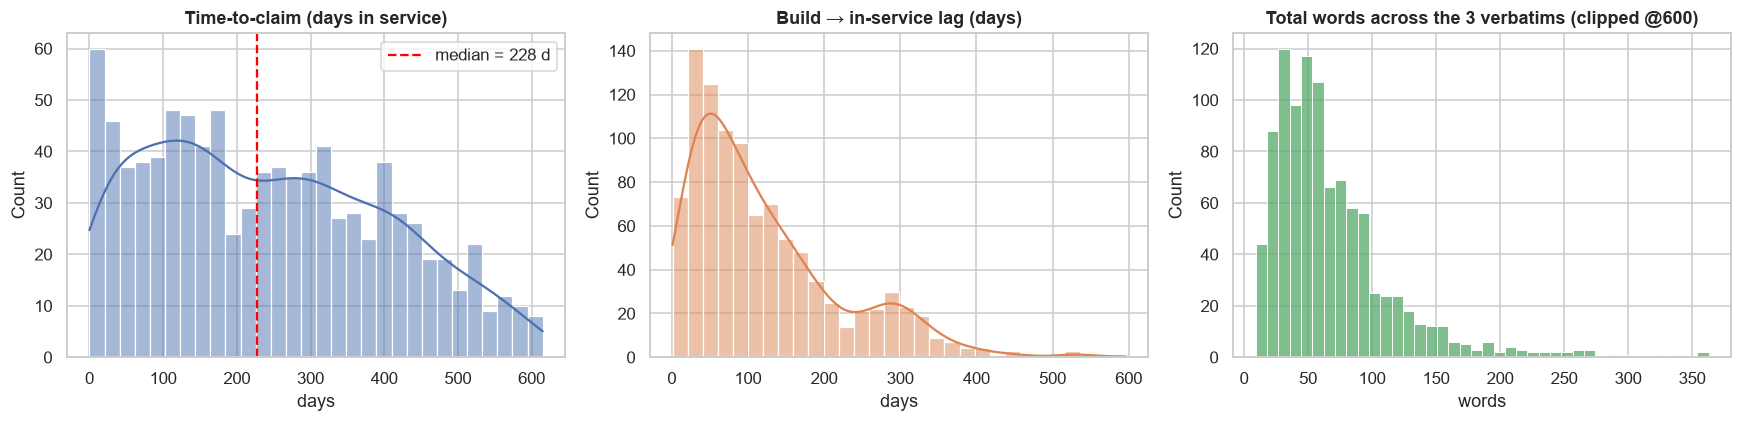

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['days_in_service_clean'].dropna(), bins=30, kde=True, ax=ax[0], color=PAL[0])
ax[0].axvline(df['days_in_service_clean'].median(), color='red', ls='--', label=f"median = {df['days_in_service_clean'].median():.0f} d")
ax[0].set_title('Time-to-claim (days in service)'); ax[0].set_xlabel('days'); ax[0].legend()
sns.histplot(df['days_build_to_inuse'], bins=30, kde=True, ax=ax[1], color=PAL[1])
ax[1].set_title('Build → in-service lag (days)'); ax[1].set_xlabel('days')
sns.histplot(df['text_words_total'].clip(upper=600), bins=40, ax=ax[2], color=PAL[2])
ax[2].set_title('Total words across the 3 verbatims (clipped @600)'); ax[2].set_xlabel('words')
plt.tight_layout(); savefig('eda_numeric')

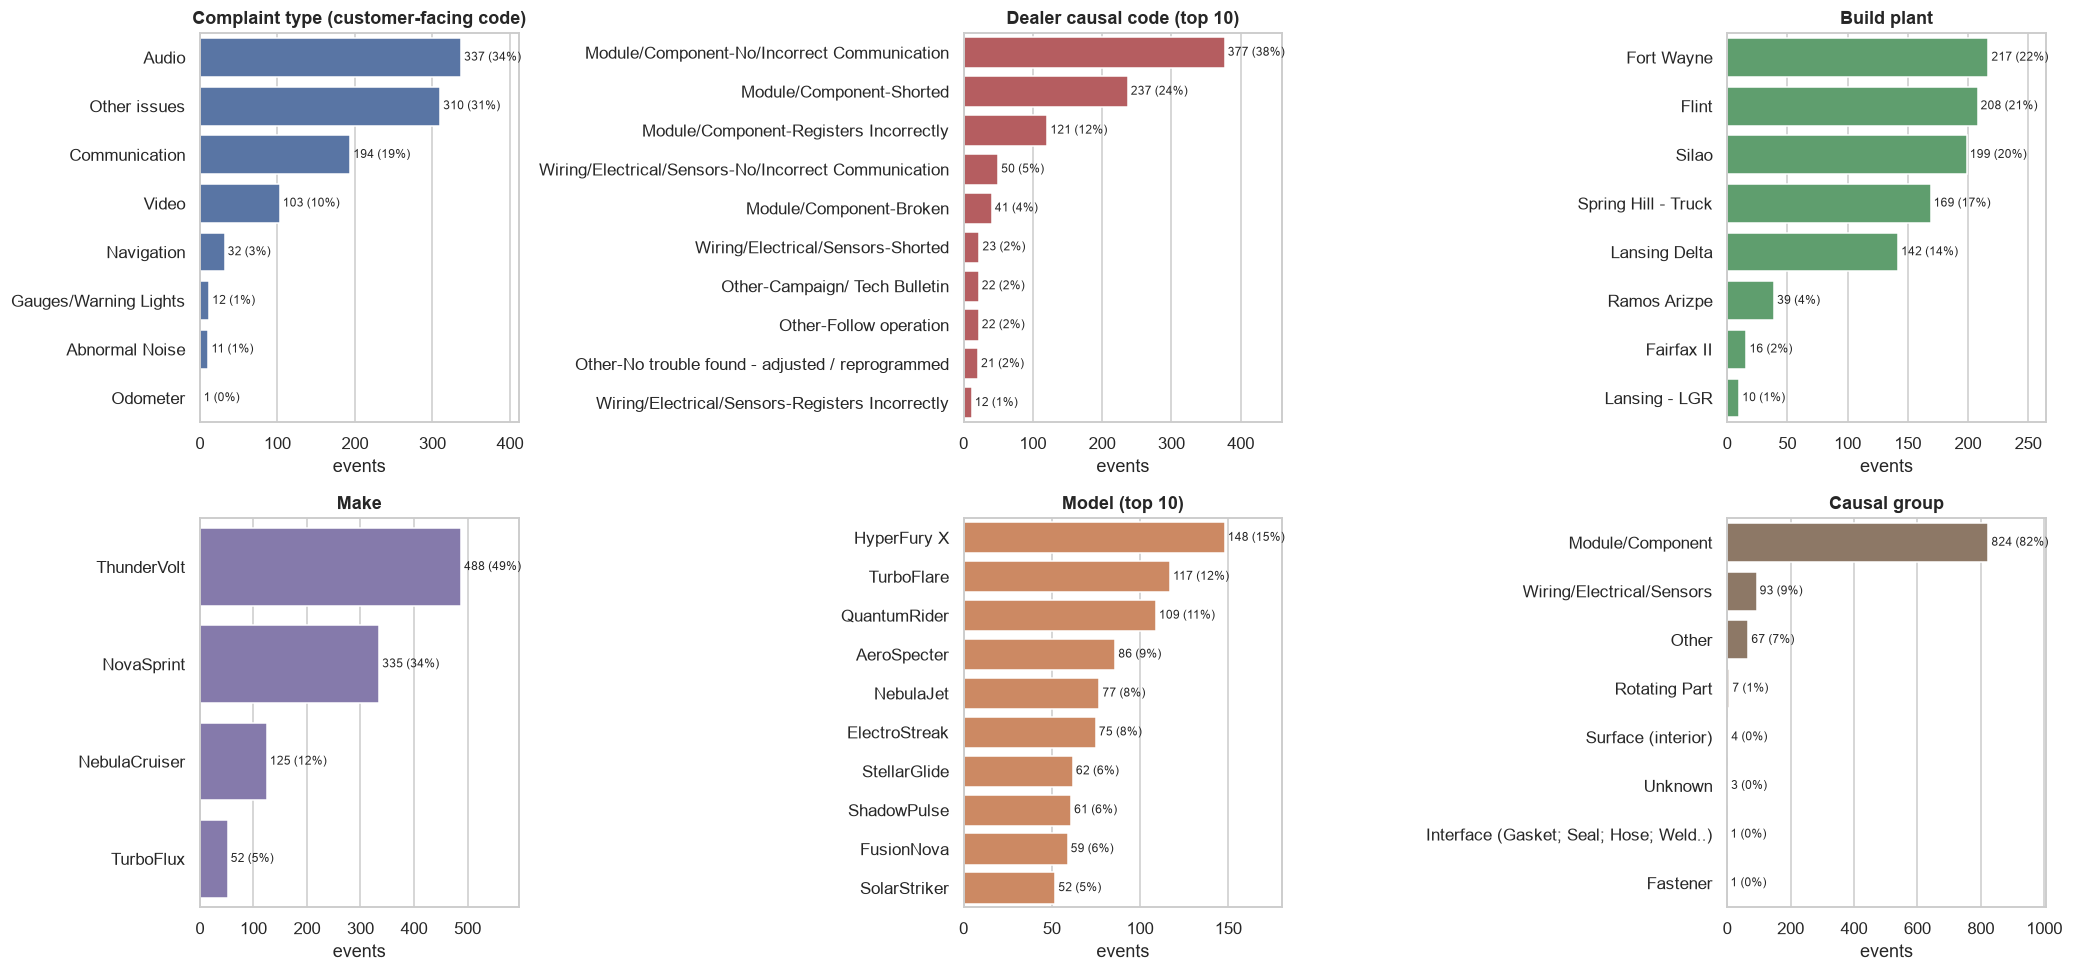

COMPLAINT_SYSTEM
Audio/Entertainment/Navigation    0.94
Features/Controls/Displays        0.06


In [13]:
# ---- 3.3 categorical frequency plots ----
def barh(ax, s, title, color=None, top=None):
    s = s.value_counts().head(top) if top else s.value_counts()
    sns.barplot(x=s.values, y=s.index, ax=ax, color=color or PAL[0])
    for i, v in enumerate(s.values): ax.text(v, i, f' {v} ({v/len(df)*100:.0f}%)', va='center', fontsize=8)
    ax.set_title(title); ax.set_xlabel('events'); ax.set_ylabel('')
    ax.set_xlim(0, s.max() * 1.22)

fig, ax = plt.subplots(2, 3, figsize=(19, 9))
barh(ax[0,0], df['COMPLAINT_DETAIL'], 'Complaint type (customer-facing code)', PAL[0])
barh(ax[0,1], df['CAUSAL_CD_DESC'], 'Dealer causal code (top 10)', PAL[3], top=10)
barh(ax[0,2], df['BUILD_PLANT_DESC'], 'Build plant', PAL[2])
barh(ax[1,0], df['MAKE'], 'Make', PAL[4])
barh(ax[1,1], df['MODEL'], 'Model (top 10)', PAL[1], top=10)
barh(ax[1,2], df['CAUSAL_GROUP'], 'Causal group', PAL[5])
plt.tight_layout(); savefig('eda_categoricals')
print(df['COMPLAINT_SYSTEM'].value_counts(normalize=True).round(3).to_string())

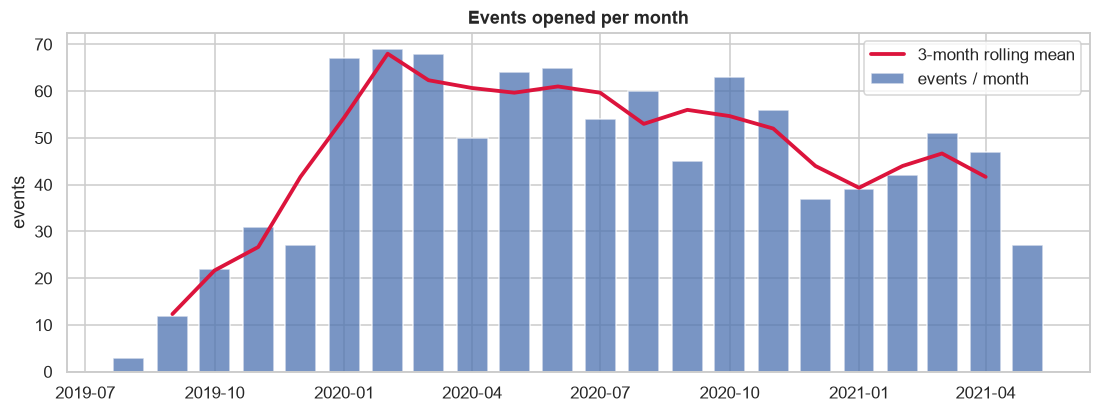

In [14]:
# ---- 3.4 monthly trend ----
m = df.groupby('opened_month').size()
m = m[m.index < '2021-06-01']                      # June-2021 has a single (partial-month) event
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(m.index, m.values, width=22, color=PAL[0], alpha=.75, label='events / month')
ax.plot(m.index, m.rolling(3, center=True).mean(), color='crimson', lw=2.5, label='3-month rolling mean')
ax.set_title('Events opened per month'); ax.legend(); ax.set_ylabel('events')
savefig('trend_monthly')
RES['monthly'] = {str(k.date()): int(v) for k, v in m.items()}

In [15]:
# ---- 3.5 plant / make cross-tab (counts and share) ----
ct = pd.crosstab(df['BUILD_PLANT_DESC'], df['MAKE'], margins=True)
display(ct)
print('\nTop-10 models by events:')
display(df.groupby(['MAKE', 'MODEL']).size().sort_values(ascending=False).head(10).to_frame('events'))
# Build window: single production window, so counts per build-week are a rough proxy for volume only
bw = df.groupby('build_week').size()
print('\nEvents by build week (all vehicles built Aug-Sep 2019):'); print(bw.to_string())

MAKE,NebulaCruiser,NovaSprint,ThunderVolt,TurboFlux,All
BUILD_PLANT_DESC,,,,,
Fairfax II,1,7,7,1,16
Flint,26,72,98,12,208
Fort Wayne,31,66,109,11,217
Lansing - LGR,0,3,5,2,10
Lansing Delta,15,45,70,12,142
Ramos Arizpe,4,15,20,0,39
Silao,23,75,94,7,199
Spring Hill - Truck,25,52,85,7,169
All,125,335,488,52,1000



Top-10 models by events:


events
MAKE          MODEL                
ThunderVolt   HyperFury X       148
              TurboFlare        117
              QuantumRider      109
NovaSprint    AeroSpecter        86
              NebulaJet          77
              ElectroStreak      75
NebulaCruiser StellarGlide       62
ThunderVolt   ShadowPulse        61
NovaSprint    FusionNova         59
TurboFlux     SolarStriker       52


Events by build week (all vehicles built Aug-Sep 2019):
build_week
2019-07-29     58
2019-08-05    184
2019-08-12    209
2019-08-19    210
2019-08-26    184
2019-09-02    155


## 4. Text mining & entity tagging
### 4.1 Free-text columns
| Column | Content | Used for |
|---|---|---|
| `CUSTOMER_VERBATIM` | What the customer / service advisor wrote (symptom, trigger) | **Failure Condition, Trigger** |
| `CAUSAL_VERBATIM` | Technician's diagnosis ("internal fault in radio", "lost comm with radio") | **Failure Component, Issue category** |
| `CORRECTION_VERBATIM` | What was done ("R&R radio and program with SPS/USB") | **Fix Component, Fix Condition** |

### 4.2 Approach – why dictionary/regex NER instead of an LLM
* The vocabulary is **closed and technical** (radio, display, amplifier, antenna, SPS, TAC …) – a curated dictionary gives deterministic, auditable tags.
* The text is noisy (ALL-CAPS, abbreviations `R&R`, `C/S`, `INOP`, numbers stripped by anonymisation, ES/FR text) → we normalise (lower-case, accent-fold) and add ES/FR synonyms.
* No external API/model downloads are needed, so the notebook is fully reproducible offline.
* **Negation handling** ("did *not* replace radio", "no updates found", "unable to duplicate") is done explicitly.
* Limitations are discussed in the report; section 4.5 validates against the 5 example rows given in the dataset. An LLM (e.g. an open-source Llama/Qwen with a JSON schema prompt) is the natural next step for the long tail – the dictionary tags can serve as weak labels / few-shot examples.

In [16]:
# ---------- 4.3 text normalisation & language detection ----------
def norm(t: str) -> str:
    """lower-case, accent-fold (écran→ecran, pantalla stays), unify quotes, collapse whitespace"""
    t = unicodedata.normalize('NFKD', str(t)).encode('ascii', 'ignore').decode()
    t = t.lower().replace("'", "'")
    return re.sub(r'\s+', ' ', t).strip()

for c in txt_cols:
    df['n_' + c] = df[c].map(norm)

ES = set('el la los las que con sin pantalla cliente falla se una por para del al cuando como esta del problema vehiculo aparece funciona'.split())
FR = set('le les des une pas est mise jour ecran avec pour client dans probleme vehicule sur au aux qui'.split())
def detect_lang(t):
    w = re.findall(r'[a-z]+', t)
    if not w: return 'en'
    es, fr = sum(x in ES for x in w), sum(x in FR for x in w)
    if max(es, fr) >= 3 and max(es, fr) / len(w) > .06: return 'es' if es >= fr else 'fr'
    return 'en'
df['language'] = (df['n_CUSTOMER_VERBATIM'] + ' ' + df['n_CAUSAL_VERBATIM'] + ' ' + df['n_CORRECTION_VERBATIM']).map(detect_lang)
print(df['language'].value_counts().to_string())
RES['language'] = df['language'].value_counts().to_dict()

language
en    984
fr     12
es      4


In [17]:
# ---------- 4.4 entity dictionaries ----------
# Every pattern is applied to accent-folded lower-case text. (pattern, scope): 'cust' = customer text only,
# 'all' = customer + technician cause text.  Tags mirror the example schema in the data (Trigger / Failure Component /
# Failure Condition / Additional Context / Fix Component / Fix Condition).

FAILURE_COMPONENTS = {
 'Radio / Head Unit':        (r"\b(radio|head ?unit|infotainment|autoradio|audio unit|audio module|receiver|hmi)\b", 'all'),
 'Display / Screen':         (r"\b(screen|display|touch ?screen|pantalla|ecran|monitor)\b", 'all'),
 'Satellite Radio (XM)':     (r"\b(xm|sirius\w*|satellite|satelite|satelit\w*)\b", 'all'),
 'Amplifier':                (r"\b(amp|amplifier|amplificador|amplificateur)\b", 'all'),
 'Speaker':                  (r"\b(speakers?|bocinas?|haut ?parleurs?|woofer|tweeter)\b", 'all'),
 'Antenna / Coax Cable':     (r"\b(antenna|antena|antenne|coax\w*)\b", 'all'),
 'USB Port / Media Input':   (r"\b(usb (?:port|hub|cable|connector|device|drive|stick|input)s?|aux (?:port|input|jack)|media hub)\b", 'all'),
 'Telematics / OnStar':      (r"\b(onstar|on star|tcicm|tcim|telematics?|telemmatics)\b", 'all'),
 'Bluetooth / Phone':        (r"\b(bluetooth|blue tooth|carplay|android auto|iphone|smartphone|hands ?free|telefono|celular|jumelage|phone (?:will not|won'?t|does not|doesn'?t|not|disconnect\w*|drops?|connect\w*|pair\w*|call\w*|audio|book|contacts)|(?:connect|pair|sync)\w* (?:to |with )?(?:the |my |his |her )?(?:cell ?)?phone)\b", 'cust'),
 'Navigation / GPS':         (r"\b(navigation|navigacion|navegacion|nav|gps|maps?)\b", 'all'),
 'Wi-Fi / Hotspot':          (r"\b(wi-?fi|hotspot|hot spot)\b", 'all'),
 'Rear Camera':              (r"\b(camera|camara|rvc|rear (?:view|vision))\b", 'all'),
 'Control Buttons / Knobs':  (r"\b(knobs?|buttons?|steering wheel controls?|swc|volume control|boton\w*|bouton\w*)\b", 'all'),
 'Instrument Cluster':       (r"\b(instrument cluster|cluster|odometer|gauges?|speedometer)\b", 'all'),
 'Software / Firmware':      (r"\b(software|firmware|outdated|out of date|corrupt\w*|glitch\w*|incorrect version|needs? (?:an? )?update)\b", 'causal'),
 'Wiring / Harness / Connector': (r"\b((?:repair\w*|replac\w*|corrod\w*|chafed|pinched|frayed|damaged|loose|backed out|broken|bent) (?:\w+ ){0,3}(?:wir(?:e|es|ing)|harness|connectors?|terminals?|cable|pins?)|(?:wir(?:e|es|ing)|harness|connectors?|terminals?|pins?) (?:\w+ ){0,3}(?:corrod\w*|chafed|pinched|frayed|damaged|loose|backed out|broken|bent|repair\w*)|found (?:an? )?(?:open|short|high resistance) (?:\w+ ){0,3}(?:wir\w*|circuit|harness|connector))\b", 'causal'),
 'Battery / Power Supply':   (r"\b((?:low|dead|weak|drained?|discharged?|parasitic) (?:\w+ ){0,2}(?:battery|voltage)|battery (?:\w+ ){0,2}(?:drain\w*|dead|discharg\w*|low|weak)|low voltage|undervoltage|bateria (?:descargada|baja))\b", 'all'),
}
FAILURE_CONDITIONS = {
 'Black / Blank Screen':     (r"\b(black(?:ed)? ?out|black screen|blank|dark screen|screen (?:\w+ )?(?:black|blank|dark|off|out|dead|dim)|pantalla (?:\w+ )?(?:negra|negro|obscura|oscura|apagada|en blanco)|ecran (?:noir|vide|blanc|eteint)|no display|display (?:is )?(?:off|out|dead))", 'all'),
 'No Sound / Audio Loss':    (r"\b(no (?:sound|audio|volume|music)|(?:sound|audio|volume) (?:is |was )?(?:cuts?|cutting|drops?|dropping|lost|gone|out|off)|loses? (?:sound|audio)|cuts? out|cutting out|mutes?|muting|sin (?:sonido|audio)|pas de son|sans son)\b", 'all'),
 'Inoperative / Dead':       (r"\b(inop\w*|inoperable|inoperative|not working|does ?n[o']?t work|do(?:es)? not work|won'?t (?:turn|come|power|work)|will not (?:turn|come|power|work)|dead|stopped working|quit working|no funciona|ne fonctionne pas|not operat\w+|no power|does not turn on)\b", 'all'),
 'Intermittent Operation':   (r"\b(intermittent\w*|at times|sometimes|randomly|random|on and off|comes? and goes|come and go|occasional\w*|periodic\w*|from time to time|a veces|parfois)\b", 'all'),
 'Reboot / Restart / Reset': (r"\b(reboot\w*|re-?start\w*|resets? (?:by itself|itself|randomly|on its own|again|and|to factory)|resetting|keeps resetting|resets randomly|shuts? (?:itself )?(?:off|down)|power cycl\w*|factory agreements?)\b", 'all'),
 'Freeze / Lag / Unresponsive': (r"\b(freez\w*|froze\w*|frozen|lock(?:s|ed)? ?up|lags?|laggy|slow(?:ly)?|unresponsive|not respond\w*|does not respond|no response|stuck|hangs?|hanging|se congela|se traba)\b", 'all'),
 'Communication Loss / Network Fault': (r"\b((?:lost|loss of|loss|no|lack of|invalid) (?:\w+ ){0,2}comm\w*|comm\w* (?:loss|lost|error|fault|failure|issue|problem)|bus (?:off|error|fault)|ethernet|serial data|network (?:fault|error))\b", 'all'),
 'Bluetooth / Phone Connection Failure': (r"\b(bluetooth\w* (?:\w+ ){0,3}(?:not|won'?t|will not|disconnect\w*|drop\w*|fail\w*|issue|problem|connect\w*|pair\w*)|(?:not|won'?t|will not|unable to|cannot|can'?t|fail\w* to|doesn'?t|does not) (?:\w+ ){0,2}(?:connect|pair|sync|link)\w*|disconnect\w*|cannot make (?:a )?calls?|unable to (?:make|receive|place) (?:a )?(?:calls?|phone)|carplay|android auto)\b", 'cust'),
 'Satellite Signal Loss':    (r"\b(satellite|satelite|xm|sirius\w*) (?:\w+ ){0,4}(?:signal|reception|lost|not|no|error|unavailable|work\w*|drop\w*|cut\w*|activation|subscription)", 'all'),
 'Static / Noise / Poor Audio': (r"\b(static|noises?|noisy|distort\w*|crackl\w*|buzz\w*|humming|poor reception|interference|ruido|bruit|statique|garbled|popping|low volume|volume (?:\w+ ){0,3}(?:chang\w*|fluctuat\w*|up and down|too))\b", 'all'),
 'Erratic / Self-Switching':  (r"\b(by itself|on its own|itself (?:switch|chang|turn|go)\w*|switch\w* (?:between|stations?|sources?)|changes? (?:stations?|sources?|channel)|erratic\w*|ghost\w*|se cambia solo|tout seul)\b", 'all'),
 'Controls / Touch Unresponsive': (r"\b((?:buttons?|knobs?|controls?|touch ?(?:screen)?|volume|steering wheel controls?) (?:\w+ ){0,3}(?:not|do(?:es)?n'?t|stop\w*|no|unresponsive|inop\w*|fail\w*|work\w*|grayed|greyed)|grayed out|greyed out|cannot control|can ?not control)\b", 'all'),
 'Navigation / GPS Error':   (r"\b((?:nav\w*|gps|maps?) (?:\w+ ){0,4}(?:not|no|wrong|error|inop\w*|issue|problem|fail\w*|work\w*|freez\w*|lost|incorrect|location)|wrong location|incorrect location|no gps)\b", 'all'),
 'Rear Camera Issue':        (r"\b(camera|camara|rvc) (?:\w+ ){0,5}?(?:not|no|black|blank|inop\w*|fail\w*|work\w*|dark|lines|delay\w*)|\b(?:not|no|black|blank|dark) (?:\w+ ){0,3}(?:rear|back ?up) (?:view|vision|camera)", 'all'),
 'Wi-Fi / OnStar Connection Failure': (r"\b(wi-?fi|hotspot|hot spot|onstar|on star)\b (?:\w+ ){0,6}?(?:not|no|fail\w*|declin\w*|unable|disconnect\w*|inop\w*|error)", 'cust'),
 'Error / Warning Message':  (r"\b(error|warning|message|prompt|alert|notification)\b", 'cust'),
}
TRIGGERS = {
 'When Reversing':          (r"\b(revers\w*|backing up|marcha atras|en reversa|marche arriere)\b", 'all'),
 'At Start-up / Ignition':  (r"\b(start ?up|start-up|(?:start|started|starting) (?:the )?(?:car|vehicle|engine|veh)|when (?:he |she |it )?starts?|upon start\w*|remote start\w*|ignition (?:on|cycle)|key (?:on|cycle)|after (?:starting|start)|cold start|arranque|demarrage|when started|first start)\b", 'all'),
 'After Software Update':   (r"\b(after (?:the |a |an )?(?:software |ota |radio )?(?:update|updated|programming|reprogram\w*)|since (?:the |an |a )?(?:update|reprogram\w*)|depuis la mise a jour|despues de (?:la )?actualiz\w*|post[- ]update|following (?:the )?update)\b", 'all'),
 'Phone / Device Connection': (r"\b(when (?:connecting|connected|pairing|plugging)|connect\w* (?:a |the |his |her )?(?:phone|device|iphone)|plug\w* in|phone (?:is )?(?:connected|paired))\b", 'cust'),
 'Weather / Temperature':   (r"\b(cold (?:weather|temps?|start|morning|day|out)|in the cold|winter|rain\w*|humid\w*|hot weather|extreme (?:heat|cold)|temperature|weather|snow|moisture|water intrusion)\b", 'all'),
 'After Parking / Overnight': (r"\b(after (?:sitting|being parked|parking)|parked|overnight|sitting for)\b", 'cust'),
}
ADDITIONAL_CONTEXT = {
 'While Driving':           (r"\b(while driving|when driving|while (?:the )?(?:vehicle|car) (?:is )?(?:in motion|moving)|in motion|highway speed|on the highway|driving down|en conduccion)\b", 'all'),
 'Repeat Visit / Recurring': (r"\b(returned|second visit|came back|repeat\w*|previous(?:ly)? (?:repair|replaced)|recurring|re-?occur\w*|condition persists|persist\w*|still (?:has|doing|having|occurs)|again)\b", 'all'),
 'Loaner / Customer Transport': (r"\b(ctp|loaner|loan vehicle|rental|shuttle)\b", 'all'),
}
# --- technician side (CORRECTION_VERBATIM) ---
REPL = r"(?:replac\w*|r ?& ?r|r/r|r and r|remplac\w*|reempl\w*|swap\w*|installed (?:a )?new|new|exchang\w*)"
FIX_COMP_RX = {
 'Radio':             r"(?:radio|head ?unit|receiver|audio unit|infotainment)",
 'Display':           r"(?:display|screen|pantalla|ecran)",
 'Antenna':           r"(?:antenna|antena|coax\w*)",
 'Amplifier':         r"(?:amplifier|amp)",
 'Speaker':           r"(?:speakers?)",
 'Telematics Module': r"(?:tcicm|tcim|telematics|onstar|tcu)",
 'Wiring / Connector': r"(?:wir(?:e|es|ing)|harness|connectors?|terminals?|cable)",
 'Camera':            r"(?:camera)",
 'USB Hub / Port':    r"(?:usb (?:hub|port))",
}
FIX_COND = {
 'Programmed / Reflashed': r"\b(program\w*|reflash\w*|flash\w*|sps|usb (?:file|programming|update|transfer)|software (?:update|download|install\w*)|updat\w*|calibrat\w*|ota|programacion|mise a jour)\b",
 'Repaired / Cleaned':     r"\b(repair\w*|clean\w*|re-?seat\w*|re-?secur\w*|tighten\w*|dielectric|grease|splic\w*|re-?rout\w*|re-?pin\w*|crimp\w*)\b",
 'Reset / Reboot':         r"\b(hard reset|master reset|factory reset|reboot\w*|disconnect(?:ed)? (?:the )?battery|battery disconnect|reset (?:the )?(?:radio|system|module))\b",
 'No Fault Found':         r"\b(unable to (?:duplicate|verify|replicate|confirm)|could ?n[o']?t (?:duplicate|verify|replicate|confirm|repeat)|cannot (?:duplicate|verify|replicate)|no problem found|no trouble found|ntf|nff|not able to (?:duplicate|verify))\b",
}

# negation / noise removal applied before fix-side matching
def clean_fix(t):
    t = re.sub(r"\b(?:did ?n[o']?t|do(?:es)? not|not|no need to|no)\s+(?:need to\s+)?(?:replac\w*|r ?& ?r|install\w*)", ' ', t)
    t = re.sub(r"\b(?:no|none|not)\b (?:\w+ ){0,2}(?:updat\w*|bulletins?|software|programming)(?: (?:found|available|applicable|apply|listed|supported|possible))?", ' ', t)
    return t

def scoped_text(row, scope):
    if scope == 'cust':   return row['n_CUSTOMER_VERBATIM']
    if scope == 'causal': return row['n_CAUSAL_VERBATIM']
    return row['n_CUSTOMER_VERBATIM'] + ' . ' + row['n_CAUSAL_VERBATIM']       # 'all'

def tag_from_dict(row, dct):
    """return tags ordered by first appearance (earliest mention first), de-duplicated"""
    hits = []
    for tag, (rx, scope) in dct.items():
        t = scoped_text(row, scope)
        m = re.search(rx, t)
        if m: hits.append((m.start() + (0 if scope != 'causal' else 10_000), tag))
    return [t for _, t in sorted(hits)]

def fix_components(row):
    t = clean_fix(row['n_CORRECTION_VERBATIM'])
    out = []
    for tag, rx in FIX_COMP_RX.items():
        if re.search(rf"\b{REPL}\W+(?:\w+\W+){{0,5}}?{rx}\b|\b{rx}\W+(?:\w+\W+){{0,2}}?{REPL}\b", t):
            out.append(tag)
    if re.search(r"\bsps\b", t): out.append('SPS')
    if re.search(r"\busb\b", t): out.append('USB')
    if re.search(r"\b(ota|over the air)\b", t): out.append('OTA')
    return out

def fix_conditions(row):
    t = clean_fix(row['n_CORRECTION_VERBATIM'])
    out = []
    if re.search(rf"\b{REPL}\b", t) and any(re.search(rf"\b{REPL}\W+(?:\w+\W+){{0,5}}?{rx}\b|\b{rx}\W+(?:\w+\W+){{0,2}}?{REPL}\b", t) for rx in FIX_COMP_RX.values()):
        out.append('Replaced')
    for tag, rx in FIX_COND.items():
        if re.search(rx, t): out.append(tag)
    # NFF only when no part was replaced / reprogrammed (otherwise it just says 'could not duplicate, but ...')
    if 'No Fault Found' in out and len(out) > 1: out.remove('No Fault Found')
    return out or ['Not Specified']

df['Mined_Trigger']           = df.apply(lambda r: tag_from_dict(r, TRIGGERS), axis=1)
df['Mined_Failure_Component'] = df.apply(lambda r: tag_from_dict(r, FAILURE_COMPONENTS), axis=1)
df['Mined_Failure_Condition'] = df.apply(lambda r: tag_from_dict(r, FAILURE_CONDITIONS), axis=1)
df['Mined_Additional_Context'] = df.apply(lambda r: tag_from_dict(r, ADDITIONAL_CONTEXT), axis=1)
df['Mined_Fix_Component']     = df.apply(fix_components, axis=1)
df['Mined_Fix_Condition']     = df.apply(fix_conditions, axis=1)

# extras: DTC codes, escalation to the manufacturer's technical assistance centre (TAC/Techline/FSE)
all_text = df['n_CUSTOMER_VERBATIM'] + ' . ' + df['n_CAUSAL_VERBATIM'] + ' . ' + df['n_CORRECTION_VERBATIM']
df['DTC_codes']      = all_text.map(lambda t: sorted(set(re.findall(r"\b[pbcu][0-3][0-9a-f]{3}\b", t))))
df['dtc_mentioned']  = all_text.str.contains(r"\bdtcs?\b|\bcodes?\b") & ~all_text.str.contains(r"\bno (?:dtcs?|codes?)\b")
df['escalated_tac']  = all_text.str.contains(r"\b(tac|techline|tech line|fse|field service engineer|engineering)\b")
df['part_replaced']  = df['Mined_Fix_Condition'].map(lambda x: 'Replaced' in x)
df['radio_replaced'] = df.apply(lambda r: r['part_replaced'] and 'Radio' in r['Mined_Fix_Component'], axis=1)
df['reprogrammed']   = df['Mined_Fix_Condition'].map(lambda x: 'Programmed / Reflashed' in x)
df['n_symptoms']     = df['Mined_Failure_Condition'].map(len)
df['repeat_visit']   = df['Mined_Additional_Context'].map(lambda x: 'Repeat Visit / Recurring' in x)

# --- default when nothing found (same idea as 'No Additional Functionality' in the example rows) ---
for c in ['Mined_Trigger', 'Mined_Additional_Context']:
    df[c] = df[c].map(lambda x: x if x else ['None Identified'])
df['Mined_Failure_Component'] = df['Mined_Failure_Component'].map(lambda x: x if x else ['Unspecified'])
df['Mined_Failure_Condition'] = df['Mined_Failure_Condition'].map(lambda x: x if x else ['Unspecified'])
df['Mined_Fix_Component']     = df['Mined_Fix_Component'].map(lambda x: x if x else ['Unspecified'])

def flat(col):  return Counter(t for tags in df[col] for t in tags)
for col in ['Mined_Failure_Component', 'Mined_Failure_Condition', 'Mined_Trigger', 'Mined_Fix_Component', 'Mined_Fix_Condition', 'Mined_Additional_Context']:
    print(f'\n== {col} ==');  print(pd.Series(flat(col)).sort_values(ascending=False).to_string())
print('\nDTC codes found:', int((df['DTC_codes'].map(len) > 0).sum()), '| escalated to TAC/FSE:', int(df['escalated_tac'].sum()),
      '| part replaced:', int(df['part_replaced'].sum()), '| radio replaced:', int(df['radio_replaced'].sum()), '| reprogrammed:', int(df['reprogrammed'].sum()))


== Mined_Failure_Component ==
Radio / Head Unit               929
Display / Screen                423
Rear Camera                     132
Satellite Radio (XM)            131
Software / Firmware              76
Navigation / GPS                 67
Telematics / OnStar              60
Bluetooth / Phone                58
Antenna / Coax Cable             49
Control Buttons / Knobs          42
Amplifier                        26
Wi-Fi / Hotspot                  15
Unspecified                      15
Battery / Power Supply           10
Speaker                          10
Wiring / Harness / Connector      9
USB Port / Media Input            8
Instrument Cluster                6

== Mined_Failure_Condition ==
Inoperative / Dead                      316
Black / Blank Screen                    212
Intermittent Operation                  199
Unspecified                             178
Communication Loss / Network Fault      134
No Sound / Audio Loss                   132
Rear Camera Issue         

### 4.5 Validation against the 5 example rows supplied with the data
The dataset includes 5 rows with hand-labelled tags. We canonicalise their vocabulary (`Audio Unit`, `Radio Module` → `Radio / Head Unit`, …) and measure **recall** of our extractor for each tag family (did we recover what the analyst wrote?). With n = 5 this is a smoke-test, not a metric of generalisation.

In [18]:
import ast
ref = raw[raw['Trigger'].notna()].copy()
CANON = {'Audio Unit': 'Radio / Head Unit', 'Radio': 'Radio / Head Unit', 'Radio Module': 'Radio / Head Unit',
         'Display': 'Display / Screen', 'OnStar': 'Telematics / OnStar',
         'Controls Irresponsive': 'Controls / Touch Unresponsive', 'Black Screen': 'Black / Blank Screen',
         'Inoperative': 'Inoperative / Dead', 'No Sound': 'No Sound / Audio Loss', 'Malfunction': None, 'Internal Fault': None,
         'Replaced': 'Replaced', 'Programmed': 'Programmed / Reflashed', 'SPS': 'SPS', 'USB': 'USB',
         'When Reversing': 'When Reversing', 'While Driving': 'While Driving'}
rows = []
for idx, r in ref.iterrows():
    mined = df.loc[idx]
    for fam, mcol in [('Failure Component', 'Mined_Failure_Component'), ('Failure Condition', 'Mined_Failure_Condition'),
                      ('Fix Component', 'Mined_Fix_Component'), ('Fix Condition', 'Mined_Fix_Condition'),
                      ('Trigger', 'Mined_Trigger'), ('Additional Context', 'Mined_Additional_Context')]:
        cmap = dict(CANON); 
        if fam == 'Fix Component': cmap['Radio'] = 'Radio'          # fix-side vocabulary uses the short name
        given = {cmap.get(x, x) for x in ast.literal_eval(r[fam])} - {None, 'No Additional Functionality', 'No Additional Context'}
        got = set(mined[mcol])
        for g in given: rows.append({'Event id': r['Event id'], 'family': fam, 'reference tag': g, 'recovered': g in got})
val = pd.DataFrame(rows)
display(val.groupby('family')['recovered'].agg(['sum', 'count', 'mean']).rename(columns={'sum': 'recovered', 'count': 'reference tags', 'mean': 'recall'}).round(2))
print('Overall recall on reference tags: %.0f%%  (%d / %d)' % (val['recovered'].mean() * 100, val['recovered'].sum(), len(val)))
RES['validation_recall'] = float(val['recovered'].mean()); RES['validation_n'] = int(len(val))
print('\nReference tags NOT recovered:'); display(val[~val['recovered']])
side = df.loc[ref.index, ['Event id', 'Mined_Failure_Component', 'Mined_Failure_Condition', 'Mined_Fix_Component', 'Mined_Fix_Condition']]
side.join(ref[['Failure Component', 'Failure Condition', 'Fix Component', 'Fix Condition']].add_prefix('PROVIDED: '))

,recovered,reference tags,recall
family,,,
Additional Context,0,1,0.00
Failure Component,9,9,1.00
Failure Condition,3,7,0.43
Fix Component,4,8,0.50
Fix Condition,6,8,0.75
Trigger,1,1,1.00


Overall recall on reference tags: 68%  (23 / 34)

Reference tags NOT recovered:


,Event id,family,reference tag,recovered
2,D-14801,Failure Condition,Controls / Touch Unresponsive,False
3,D-14801,Failure Condition,Black / Blank Screen,False
13,D-14869,Fix Component,USB,False
20,D-14555,Failure Condition,Inoperative / Dead,False
21,D-14555,Fix Component,Radio,False
22,D-14555,Fix Condition,Replaced,False
24,D-14704,Failure Condition,Black / Blank Screen,False
25,D-14704,Fix Component,USB,False
26,D-14704,Fix Component,Radio,False
27,D-14704,Fix Condition,Programmed / Reflashed,False


,Event id,Mined_Failure_Component,Mined_Failure_Condition,Mined_Fix_Component,Mined_Fix_Condition,PROVIDED: Failure Component,PROVIDED: Failure Condition,PROVIDED: Fix Component,PROVIDED: Fix Condition
0,D-14801,"[Radio / Head Unit, Display / Screen, Telematics / OnStar, Amplifier, Software / Firmw...","[Inoperative / Dead, No Sound / Audio Loss, Reboot / Restart / Reset, Communication Lo...","[Radio, SPS, USB, OTA]","[Replaced, Programmed / Reflashed, Reset / Reboot]","['Audio Unit', 'Display']","['Controls Irresponsive', 'Black Screen']","['Radio', 'SPS']","['Replaced', 'Programmed']"
1,D-14869,"[Radio / Head Unit, Display / Screen, Telematics / OnStar]","[Inoperative / Dead, Black / Blank Screen, No Sound / Audio Loss, Communication Loss /...",[Radio],"[Replaced, Programmed / Reflashed]","['Radio', 'Display', 'Radio']","['Inoperative', 'Black Screen', 'No Sound']","['Radio', 'USB']","['Replaced', 'Programmed']"
2,D-14555,"[Radio / Head Unit, Display / Screen, Telematics / OnStar, Wi-Fi / Hotspot]","[Wi-Fi / OnStar Connection Failure, Error / Warning Message]",[Unspecified],[Not Specified],"['Display', 'OnStar', 'Radio Module']","['Inoperative', 'Inoperative', 'Internal Fault']",['Radio'],['Replaced']
3,D-14704,[Display / Screen],[Unspecified],"[Antenna, Wiring / Connector]",[Replaced],['Display'],['Black Screen'],"['Radio', 'USB']","['Replaced', 'Programmed']"
4,D-15142,"[Satellite Radio (XM), Display / Screen, Radio / Head Unit]","[Error / Warning Message, Satellite Signal Loss, Inoperative / Dead]","[Radio, USB]","[Replaced, Programmed / Reflashed]",['Radio'],['Malfunction'],['Radio'],['Replaced']


## 5. Issue-type categorisation
Entities are grouped into **eight higher-level issue types** with an *evidence-scoring* rule set. Each category earns points from (a) technician wording in cause/correction text and (b) the dealer's structured causal code, so that text and codes cross-validate each other. The highest score becomes `Issue_Category`; the runner-up (if ≥2 points) is stored as `Issue_Category_Secondary` – many events genuinely have two layers (e.g. *"lost communication with radio → internal fault → radio replaced"*).

| Category | Typical evidence |
|---|---|
| **Component Failure** | "internal fault/failure/short", radio replaced, code *Shorted/Broken/Worn/Damaged* |
| **Communication / Network Fault** | "lost communication", Ethernet/bus errors, code *No/Incorrect Communication* |
| **Software / Firmware Glitch** | reprogramming / SPS / update resolved it, code *Incorrect Version / Campaign / TSB* |
| **Electrical / Wiring Issue** | repaired connector/harness, corrosion, low voltage, code *Wiring/Electrical* |
| **Antenna / Reception Issue** | antenna or coax replaced / faulty |
| **Assembly / Installation Quality** | pinched, not seated, mis-routed, loose connector, aftermarket |
| **No Fault Found / Unverified** | "unable to duplicate", code *No trouble found* |
| **Other / Unclassified** | not enough evidence |

In [19]:
tech = (df['n_CAUSAL_VERBATIM'] + ' . ' + df['n_CORRECTION_VERBATIM'])      # technician-side text
CD = df['CAUSAL_CD_DESC'].str.lower()

RX = {
 'CF_strong': r"\b(internal(?:ly)? (?:fault|failure|failed|short\w*|malfunction\w*|defect\w*|issue|problem)|(?:radio|module|unit|display|amplifier|amp|screen|assembly|hardware) (?:internal\w* )?(?:is |was |has )?(?:fail\w*|faulty|defective|bad|shorted|dead|burnt|burned|damaged|broken)|(?:faulty|defective|bad|failed|shorted|internal) (?:radio|module|unit|display|amplifier|screen|assembly|hardware)|shorted|hardware (?:fault|failure|failed)|falla interna|defaillance)\b",
 'COMM':      r"\b((?:lost|loss of|loss|no|lack of|invalid) (?:\w+ ){0,2}comm\w*|comm\w* (?:loss|lost|error|fault|failure|issue|problem)|ethernet|bus (?:off|error|fault)|serial data|network (?:fault|error)|perdida de comunicacion)\b",
 'SW':        r"\b(software (?:issue|problem|glitch|fault|corrupt\w*|bug|related|update (?:needed|required|available|fix\w*))|firmware|corrupt\w*|glitch\w*|outdated|out of date|incorrect (?:software|version|calibration)|campaign|tsb|technical service bulletin|per bulletin|reflash\w*|updated software|updates? (?:performed|completed|installed|applied|resolved|fixed)|performed (?:the )?(?:software )?update|software updated?|sw update)\b",
 'ELEC':      r"\b((?:repair\w*|corrod\w*|chafed|pinched|frayed|spliced?) (?:\w+ ){0,3}(?:wir(?:e|es|ing)|harness|connectors?|terminals?|pins?|ground)|(?:wir(?:e|es|ing)|harness|connectors?|terminals?|pins?|ground) (?:\w+ ){0,3}(?:corrod\w*|chafed|pinched|frayed|damaged|broken|bent|repair\w*|open|shorted)|found (?:an? )?(?:open|short|high resistance|corrosion|loose|pinched|chafed|broken|backed out)|blown fuse|low (?:battery )?voltage|battery (?:drain\w*|dead|discharg\w*)|poor (?:contact|connection|ground)|fretting)\b",
 'ANT':       r"\b((?:antenna|antena|antenne|coax\w*) (?:\w+ ){0,4}(?:bad|faulty|defective|damaged|failed|open|high resistance|shorted|water|corrod\w*|replac\w*)|(?:replac\w*|r ?& ?r|new) (?:\w+ ){0,3}(?:antenna|antena|coax\w*))\b",
 'ASSY':      r"\b(pinched|not (?:fully )?(?:seated|connected|plugged|latched|installed)|improperly (?:installed|seated|connected|routed)|incorrectly (?:installed|routed|seated)|unplugged|came (?:loose|unplugged|disconnected)|left (?:disconnected|unplugged)|loose (?:connector|connection|plug)|misrout\w*|assembly (?:error|defect|issue|problem)|build (?:issue|defect)|plant (?:issue|defect)|backed out|aftermarket|dealer[- ]installed|rattl\w*)\b",
 'NFF':       r"\b(unable to (?:duplicate|verify|replicate|confirm)|could ?n[o']?t (?:duplicate|verify|replicate|confirm|repeat)|cannot (?:duplicate|verify|replicate)|no problem found|no trouble found|ntf|nff|not able to (?:duplicate|verify))\b",
}
has = {k: tech.map(lambda t, rx=rx: bool(re.search(rx, clean_fix(t)))) for k, rx in RX.items()}

score = pd.DataFrame(0, index=df.index, columns=['Component Failure', 'Communication / Network Fault', 'Software / Firmware Glitch',
                     'Electrical / Wiring Issue', 'Antenna / Reception Issue', 'Assembly / Installation Quality', 'No Fault Found / Unverified'])
# --- Component failure ---
score['Component Failure'] += 3 * has['CF_strong']
score['Component Failure'] += 2 * (df['part_replaced'] & df['Mined_Fix_Component'].map(lambda x: any(c in x for c in ['Radio', 'Display', 'Amplifier', 'Speaker', 'Telematics Module', 'USB Hub / Port', 'Camera'])))
score['Component Failure'] += 2 * CD.str.contains(r'shorted|broken|worn|damaged|discharge') & CD.str.startswith('module')
score['Component Failure'] += 1 * CD.str.contains('registers incorrectly')
# --- Communication ---
score['Communication / Network Fault'] += 2 * has['COMM']
score['Communication / Network Fault'] += 2 * CD.str.contains('no/incorrect communication')
score['Communication / Network Fault'] += 1 * df['Mined_Failure_Condition'].map(lambda x: 'Communication Loss / Network Fault' in x)
# --- Software ---
score['Software / Firmware Glitch'] += 2 * has['SW']
score['Software / Firmware Glitch'] += 2 * (df['reprogrammed'] & ~df['part_replaced'])
score['Software / Firmware Glitch'] += 4 * CD.str.contains('incorrect version|campaign|tech bulletin')
score['Software / Firmware Glitch'] += 2 * CD.str.contains('adjusted / reprogrammed')
score['Software / Firmware Glitch'] += 1 * df['Mined_Trigger'].map(lambda x: 'After Software Update' in x)
# --- Electrical ---
score['Electrical / Wiring Issue'] += 3 * has['ELEC']
score['Electrical / Wiring Issue'] += 3 * CD.str.startswith('wiring/electrical')
score['Electrical / Wiring Issue'] += 2 * CD.str.contains('poor contact')
score['Electrical / Wiring Issue'] += 2 * df['Mined_Fix_Component'].map(lambda x: 'Wiring / Connector' in x)
# --- Antenna ---
score['Antenna / Reception Issue'] += 3 * has['ANT']
score['Antenna / Reception Issue'] += 4 * df['Mined_Fix_Component'].map(lambda x: 'Antenna' in x)
# --- Assembly ---
score['Assembly / Installation Quality'] += 3 * has['ASSY']
# --- NFF ---
score['No Fault Found / Unverified'] += 3 * (has['NFF'] & ~df['part_replaced'])
score['No Fault Found / Unverified'] += 3 * CD.str.contains('no trouble found')

PRIORITY = ['Assembly / Installation Quality', 'Electrical / Wiring Issue', 'Antenna / Reception Issue', 'Component Failure',
            'Communication / Network Fault', 'Software / Firmware Glitch', 'No Fault Found / Unverified']   # tie-break order
sc = score[PRIORITY]
rank = sc.apply(lambda r: sorted(PRIORITY, key=lambda c: (-r[c], PRIORITY.index(c))), axis=1)
top1 = rank.str[0]; top2 = rank.str[1]
df['Issue_Category'] = np.where(sc.max(axis=1) >= 2, top1, 'Other / Unclassified')
df['Issue_Category_Secondary'] = np.where(sc.apply(lambda r: sorted(r, reverse=True)[1], axis=1) >= 2, top2, '')
df['Issue_Score'] = sc.max(axis=1)

# sub-type for the dominant category: is the hardware fault explicitly documented, or was the part swapped on TAC advice / trial basis?
cf_strong = has['CF_strong']
df['Issue_Subtype'] = ''
cfm = df['Issue_Category'].eq('Component Failure')
df.loc[cfm & cf_strong, 'Issue_Subtype'] = 'Internal hardware fault documented'
df.loc[cfm & ~cf_strong & df['escalated_tac'], 'Issue_Subtype'] = 'Replaced on TAC/engineering advice (no fault detail)'
df.loc[cfm & ~cf_strong & ~df['escalated_tac'], 'Issue_Subtype'] = 'Replaced – cause not documented'
print(df.loc[cfm, 'Issue_Subtype'].value_counts().to_string()); RES['cf_subtype'] = df.loc[cfm, 'Issue_Subtype'].value_counts().to_dict()
cat_counts = df['Issue_Category'].value_counts()
print(cat_counts.to_string()); print('\nSecondary category present in %.0f%% of events' % ((df['Issue_Category_Secondary'] != '').mean() * 100))
RES['issue_category'] = cat_counts.to_dict()

# agreement of mined categories with the dealer-coded causal group
display(pd.crosstab(df['Issue_Category'], df['CAUSAL_GROUP'], margins=True))
display(pd.crosstab(df['Issue_Category'], df['CAUSAL_DETAIL']).loc[:, df['CAUSAL_DETAIL'].value_counts().head(8).index])

Issue_Subtype
Internal hardware fault documented                      340
Replaced – cause not documented                         232
Replaced on TAC/engineering advice (no fault detail)    132
Issue_Category
Component Failure                  704
Communication / Network Fault      120
Electrical / Wiring Issue           84
Software / Firmware Glitch          59
Antenna / Reception Issue           11
Assembly / Installation Quality      8
Other / Unclassified                 8
No Fault Found / Unverified          6

Secondary category present in 63% of events


CAUSAL_GROUP,Fastener,Interface (Gasket; Seal; Hose; Weld..),Module/Component,Other,Rotating Part,Surface (interior),Unknown,Wiring/Electrical/Sensors,All
Issue_Category,,,,,,,,,
Antenna / Reception Issue,0,0,11,0,0,0,0,0,11
Assembly / Installation Quality,0,0,8,0,0,0,0,0,8
Communication / Network Fault,0,1,102,4,0,0,1,12,120
Component Failure,0,0,653,27,3,4,1,16,704
Electrical / Wiring Issue,0,0,20,1,0,0,0,63,84
No Fault Found / Unverified,0,0,1,5,0,0,0,0,6
Other / Unclassified,1,0,6,0,1,0,0,0,8
Software / Firmware Glitch,0,0,23,30,3,0,1,2,59
All,1,1,824,67,7,4,3,93,1000


CAUSAL_DETAIL,No/Incorrect Communication,Shorted,Registers Incorrectly,Broken,Campaign/ Tech Bulletin,Follow operation,No trouble found - adjusted / reprogrammed,Poor Contact
Issue_Category,,,,,,,,
Antenna / Reception Issue,4,4,2,0,0,0,0,1
Assembly / Installation Quality,4,1,1,0,0,0,0,1
Communication / Network Fault,84,20,0,7,0,3,1,1
Component Failure,296,205,110,34,3,18,5,2
Electrical / Wiring Issue,37,23,8,0,0,1,0,6
No Fault Found / Unverified,0,0,0,1,0,0,5,0
Other / Unclassified,0,2,3,0,0,0,0,0
Software / Firmware Glitch,2,5,9,2,19,0,10,0


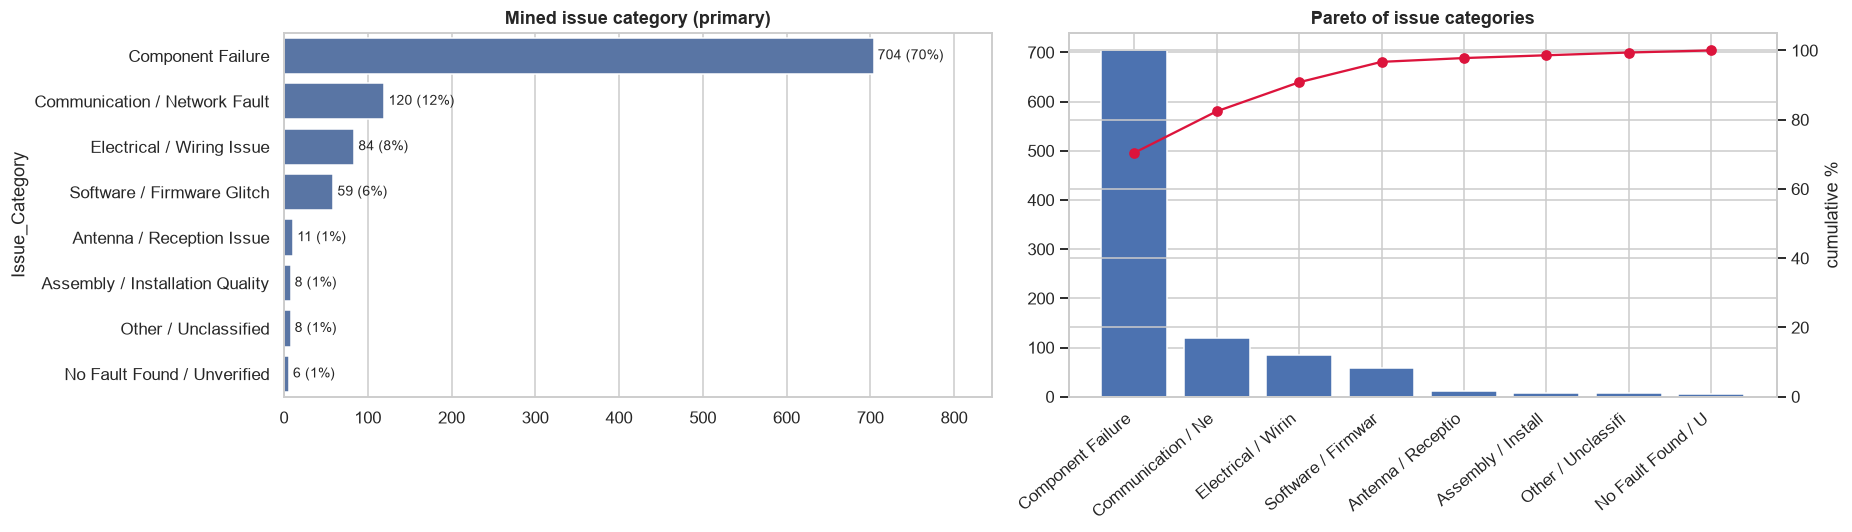

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
order = cat_counts.index
sns.barplot(x=cat_counts.values, y=order, ax=ax[0], color=PAL[0])
for i, v in enumerate(cat_counts.values): ax[0].text(v, i, f' {v} ({v/len(df)*100:.0f}%)', va='center', fontsize=9)
ax[0].set_title('Mined issue category (primary)'); ax[0].set_xlim(0, cat_counts.max() * 1.2)
cum = cat_counts.cumsum() / cat_counts.sum() * 100
ax[1].bar(range(len(cat_counts)), cat_counts.values, color=PAL[0]); ax[1].set_xticks(range(len(cat_counts))); ax[1].set_xticklabels([o[:18] for o in order], rotation=40, ha='right')
ax2 = ax[1].twinx(); ax2.plot(range(len(cat_counts)), cum.values, color='crimson', marker='o'); ax2.set_ylim(0, 105); ax2.set_ylabel('cumulative %')
ax[1].set_title('Pareto of issue categories')
plt.tight_layout(); savefig('issue_categories')

## 6. Patterns, trends and top failures
### 6.1 Most frequent failure components / conditions / pairs

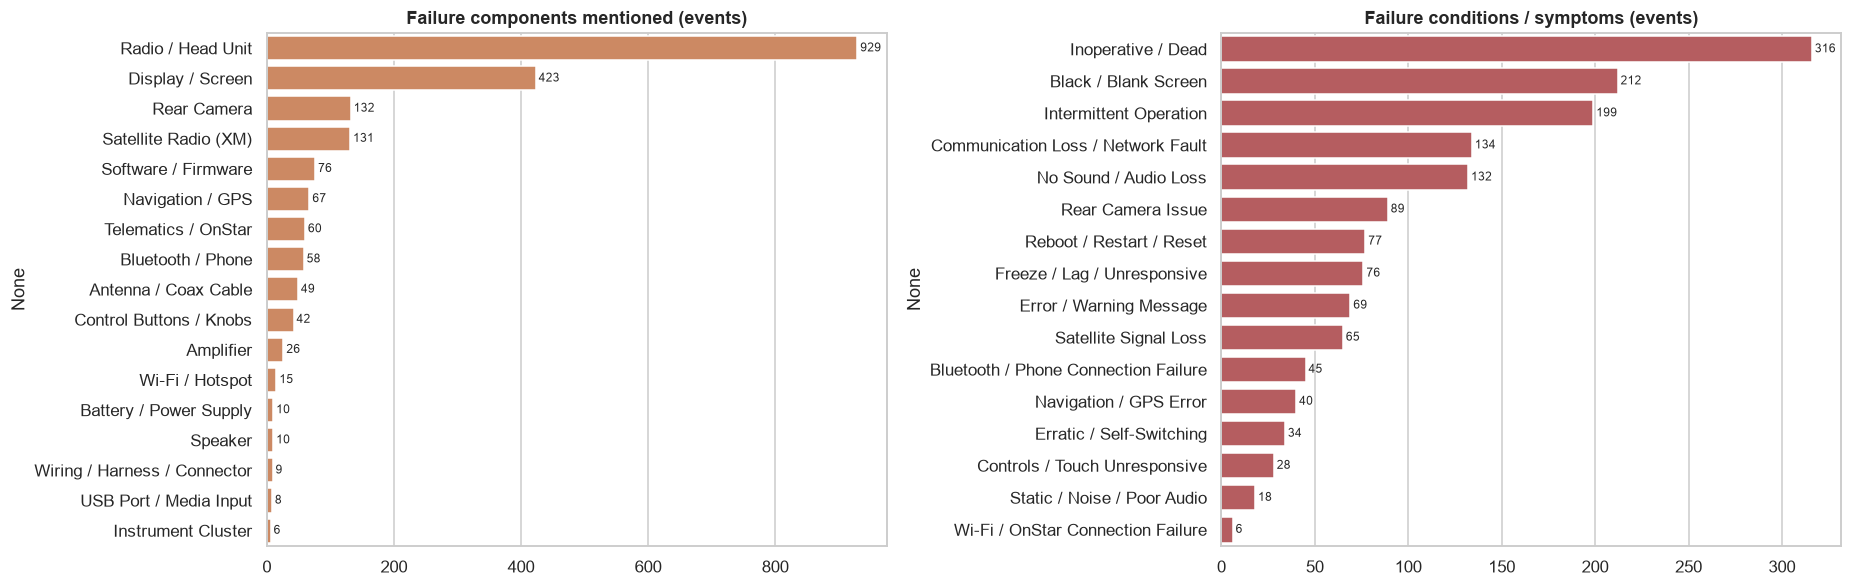

,component,condition,events
0,Radio / Head Unit,Inoperative / Dead,298
20,Radio / Head Unit,Black / Blank Screen,206
21,Display / Screen,Black / Blank Screen,188
40,Radio / Head Unit,Intermittent Operation,184
4,Display / Screen,Inoperative / Dead,131
1,Radio / Head Unit,No Sound / Audio Loss,131
3,Radio / Head Unit,Communication Loss / Network Fault,126
36,Display / Screen,Intermittent Operation,91
41,Rear Camera,Rear Camera Issue,89
46,Radio / Head Unit,Rear Camera Issue,80


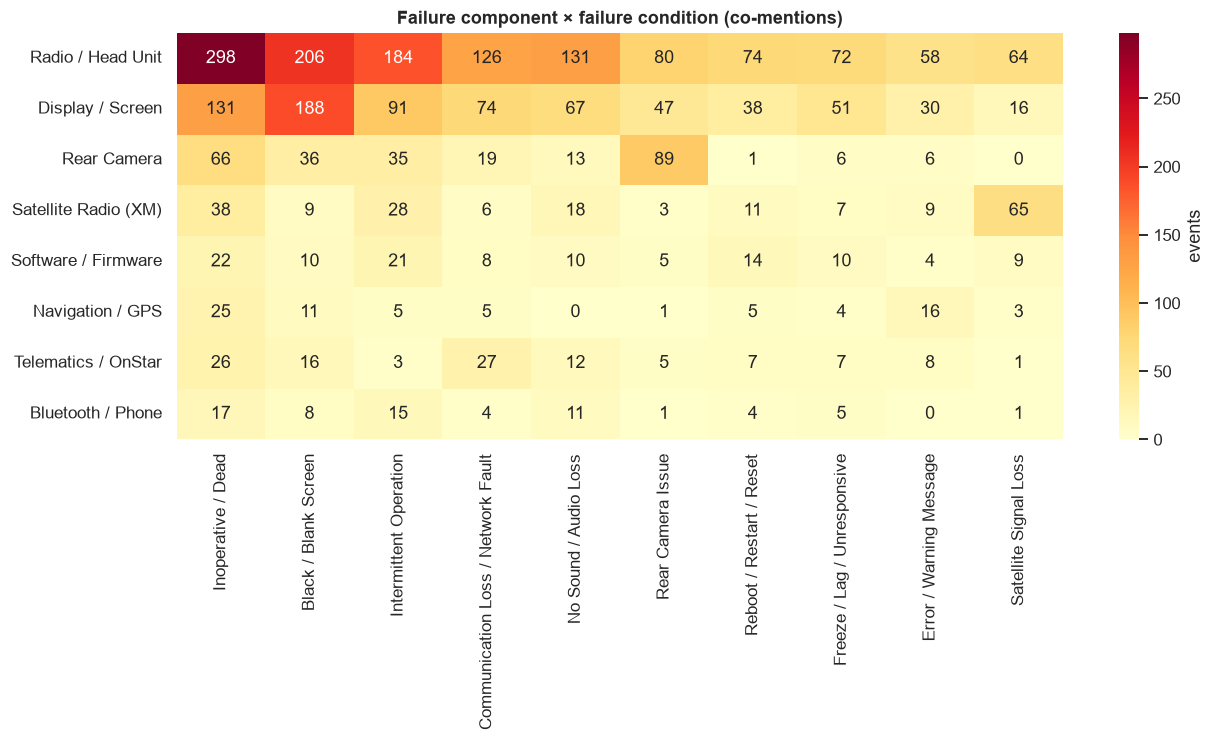

In [21]:
fc = pd.Series(flat('Mined_Failure_Component')).drop(['Unspecified'], errors='ignore').sort_values(ascending=False)
fd = pd.Series(flat('Mined_Failure_Condition')).drop(['Unspecified'], errors='ignore').sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
sns.barplot(x=fc.values, y=fc.index, ax=ax[0], color=PAL[1]); ax[0].set_title('Failure components mentioned (events)')
for i, v in enumerate(fc.values): ax[0].text(v, i, f' {v}', va='center', fontsize=8)
sns.barplot(x=fd.values, y=fd.index, ax=ax[1], color=PAL[3]); ax[1].set_title('Failure conditions / symptoms (events)')
for i, v in enumerate(fd.values): ax[1].text(v, i, f' {v}', va='center', fontsize=8)
plt.tight_layout(); savefig('failure_tags')
RES['failure_components'] = fc.head(10).to_dict(); RES['failure_conditions'] = fd.head(12).to_dict()
RES['fix_components'] = pd.Series(flat('Mined_Fix_Component')).sort_values(ascending=False).to_dict()
RES['fix_conditions'] = pd.Series(flat('Mined_Fix_Condition')).sort_values(ascending=False).to_dict()
RES['triggers'] = pd.Series(flat('Mined_Trigger')).sort_values(ascending=False).to_dict()

# component × condition pairs (co-occurrence inside the same event)
pairs = Counter((c, k) for comps, conds in zip(df['Mined_Failure_Component'], df['Mined_Failure_Condition'])
                for c in comps for k in conds if c != 'Unspecified' and k != 'Unspecified')
pair_df = pd.DataFrame([(a, b, n) for (a, b), n in pairs.items()], columns=['component', 'condition', 'events']).sort_values('events', ascending=False)
display(pair_df.head(12))
top_comps = list(fc.head(8).index); top_conds = list(fd.head(10).index)
hm = pair_df.pivot(index='component', columns='condition', values='events').reindex(index=top_comps, columns=top_conds).fillna(0)
plt.figure(figsize=(13, 4.8)); sns.heatmap(hm, annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': 'events'})
plt.title('Failure component × failure condition (co-mentions)'); plt.ylabel(''); plt.xlabel('')
savefig('component_condition_heatmap')
RES['top_pairs'] = pair_df.head(8).values.tolist()

In [22]:
# ---- 6.2 repair outcome: how are issues resolved? ----
repair = df.groupby('Issue_Category').agg(events=('Event id', 'count'), part_replaced=('part_replaced', 'mean'), radio_replaced=('radio_replaced', 'mean'),
                                           reprogrammed=('reprogrammed', 'mean'), escalated_tac=('escalated_tac', 'mean'), repeat_visit=('repeat_visit', 'mean'),
                                           median_days_in_service=('days_in_service_clean', 'median')).round(2)
display(repair.sort_values('events', ascending=False))
RES['repair_overall'] = {'part_replaced': float(df['part_replaced'].mean()), 'radio_replaced': float(df['radio_replaced'].mean()),
                         'reprogrammed': float(df['reprogrammed'].mean()), 'escalated_tac': float(df['escalated_tac'].mean()), 'repeat_visit': float(df['repeat_visit'].mean())}
RES['repair_by_cat'] = repair.reset_index().to_dict(orient='records')
print(RES['repair_overall'])

,events,part_replaced,radio_replaced,reprogrammed,escalated_tac,repeat_visit,median_days_in_service
Issue_Category,,,,,,,
Component Failure,704,0.95,0.95,0.67,0.30,0.07,209.0
Communication / Network Fault,120,0.63,0.63,0.72,0.30,0.05,230.0
Electrical / Wiring Issue,84,0.79,0.76,0.67,0.31,0.10,262.0
Software / Firmware Glitch,59,0.27,0.25,0.90,0.36,0.05,310.0
Antenna / Reception Issue,11,1.00,0.91,0.64,0.55,0.27,255.0
Assembly / Installation Quality,8,0.88,0.75,0.50,0.25,0.00,260.5
Other / Unclassified,8,0.00,0.00,0.00,0.12,0.12,281.5
No Fault Found / Unverified,6,0.67,0.67,0.33,0.17,0.00,386.0


{'part_replaced': 0.851, 'radio_replaced': 0.842, 'reprogrammed': 0.681, 'escalated_tac': 0.301, 'repeat_visit': 0.067}


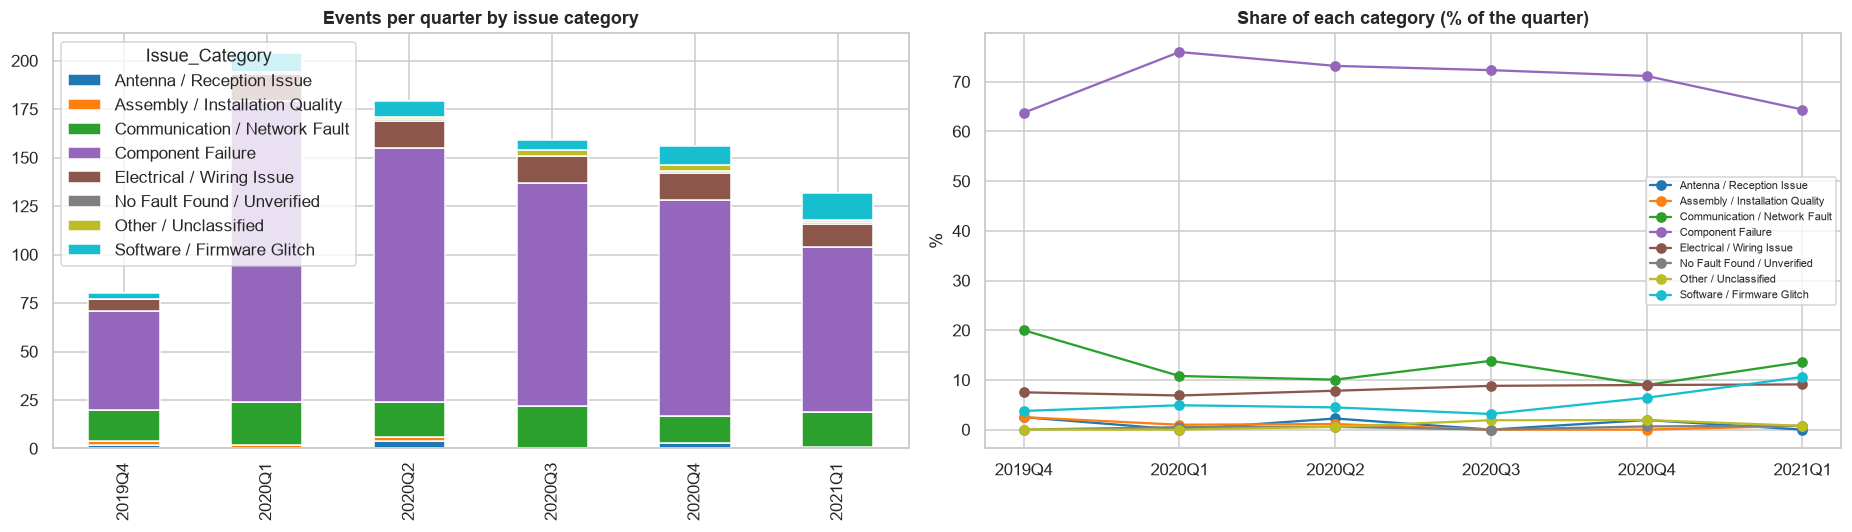

,spearman_rho,p_value,share_first_q_%,share_last_q_%
Antenna / Reception Issue,-0.52,0.295,2.5,0.0
Assembly / Installation Quality,-0.75,0.084,2.5,0.8
Communication / Network Fault,-0.37,0.468,20.0,13.6
Component Failure,-0.14,0.787,63.7,64.4
Electrical / Wiring Issue,0.94,0.005,7.5,9.1
No Fault Found / Unverified,0.75,0.084,0.0,0.8
Other / Unclassified,0.81,0.050,0.0,0.8
Software / Firmware Glitch,0.60,0.208,3.8,10.6


In [23]:
# ---- 6.3 trend of issue categories over time (quarterly share) ----
q = pd.crosstab(df['opened_quarter'], df['Issue_Category'])
q = q.loc[(q.index >= '2019Q4') & (q.index <= '2021Q1')]                      # drop the partial first/last quarters
qs = q.div(q.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
q.plot(kind='bar', stacked=True, ax=ax[0], colormap='tab10'); ax[0].set_title('Events per quarter by issue category'); ax[0].set_xlabel('')
qs.plot(kind='line', marker='o', ax=ax[1], colormap='tab10'); ax[1].set_title('Share of each category (% of the quarter)'); ax[1].set_xlabel(''); ax[1].set_ylabel('%')
ax[1].legend(fontsize=7)
plt.tight_layout(); savefig('category_trend')
# Spearman trend of share vs time
trend = {}
for c in qs.columns:
    rho, p = stats.spearmanr(np.arange(len(qs)), qs[c]); trend[c] = (round(rho, 2), round(p, 3), round(qs[c].iloc[0], 1), round(qs[c].iloc[-1], 1))
trend_df = pd.DataFrame(trend, index=['spearman_rho', 'p_value', 'share_first_q_%', 'share_last_q_%']).T
display(trend_df)
RES['category_trend'] = trend_df.reset_index().rename(columns={'index': 'category'}).to_dict(orient='records')
RES['quarters'] = {str(k): int(v) for k, v in df['opened_quarter'].value_counts().sort_index().items()}

Kruskal-Wallis days-in-service across categories: H=10.8, p=0.0129


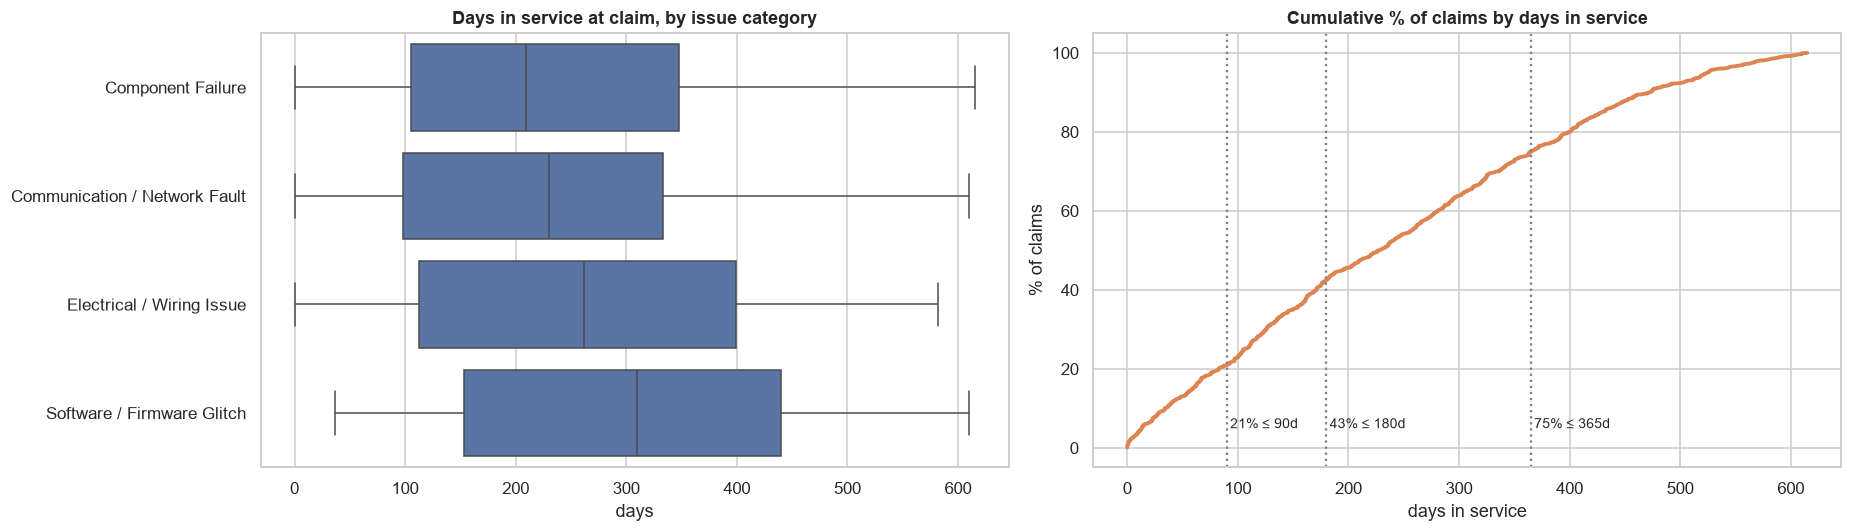


Chi-square plant × category: chi2=11.6, dof=15, p=0.711


Issue_Category,Antenna / Reception Issue,Assembly / Installation Quality,Communication / Network Fault,Component Failure,Electrical / Wiring Issue,No Fault Found / Unverified,Other / Unclassified,Software / Firmware Glitch
BUILD_PLANT_DESC,,,,,,,,
Fairfax II,0.0,0.0,12.5,87.5,0.0,0.0,0.0,0.0
Flint,1.0,1.9,11.5,68.3,11.5,0.0,0.5,5.3
Fort Wayne,1.4,0.5,13.8,67.7,8.8,0.5,1.8,5.5
Lansing - LGR,0.0,0.0,10.0,70.0,10.0,0.0,10.0,0.0
Lansing Delta,0.7,0.7,13.4,70.4,7.0,0.7,0.7,6.3
Ramos Arizpe,0.0,2.6,10.3,82.1,0.0,2.6,0.0,2.6
Silao,0.5,0.0,11.6,71.9,9.0,0.5,0.5,6.0
Spring Hill - Truck,2.4,0.6,10.1,70.4,7.1,1.2,0.0,8.3


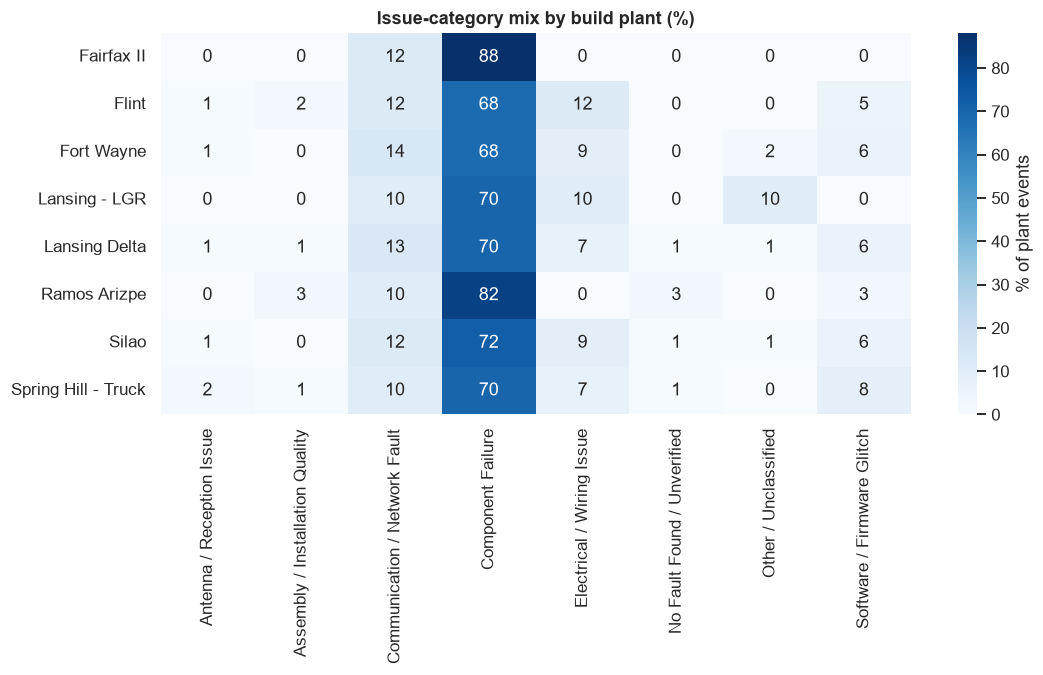

In [24]:
# ---- 6.4 time-to-claim by category, plant concentration, statistical tests ----
cats = [c for c in df['Issue_Category'].value_counts().index if (df['Issue_Category'] == c).sum() >= 15]
groups = [df.loc[df['Issue_Category'] == c, 'days_in_service_clean'].dropna() for c in cats]
H, p_kw = stats.kruskal(*groups)
print(f'Kruskal-Wallis days-in-service across categories: H={H:.1f}, p={p_kw:.3g}')
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
sns.boxplot(data=df[df['Issue_Category'].isin(cats)], y='Issue_Category', x='days_in_service_clean', order=cats, ax=ax[0], color=PAL[0])
ax[0].set_title('Days in service at claim, by issue category'); ax[0].set_xlabel('days'); ax[0].set_ylabel('')
x = np.sort(df['days_in_service_clean'].dropna()); ax[1].plot(x, np.arange(1, len(x)+1) / len(x) * 100, color=PAL[1], lw=2.5)
for d in [90, 180, 365]: ax[1].axvline(d, color='grey', ls=':'); ax[1].text(d+3, 5, f'{(x<=d).mean()*100:.0f}% ≤ {d}d', fontsize=9)
ax[1].set_title('Cumulative % of claims by days in service'); ax[1].set_xlabel('days in service'); ax[1].set_ylabel('% of claims')
plt.tight_layout(); savefig('time_to_claim')
RES['ttc_cdf'] = {str(d): float((x <= d).mean()) for d in [30, 90, 180, 365]}

# plant × category (share) + chi-square
pc = pd.crosstab(df['BUILD_PLANT_DESC'], df['Issue_Category'])
chi2, p_chi, dof, _ = stats.chi2_contingency(pc.loc[pc.sum(axis=1) >= 30, pc.sum() >= 15])
print(f'\nChi-square plant × category: chi2={chi2:.1f}, dof={dof}, p={p_chi:.3g}')
display((pc.div(pc.sum(axis=1), axis=0) * 100).round(1))
plt.figure(figsize=(11, 4.5)); sns.heatmap((pc.div(pc.sum(axis=1), axis=0) * 100).round(0), annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of plant events'})
plt.title('Issue-category mix by build plant (%)'); plt.ylabel(''); plt.xlabel(''); savefig('plant_category')
RES['chi2_plant'] = {'chi2': float(chi2), 'dof': int(dof), 'p': float(p_chi)}; RES['kruskal'] = {'H': float(H), 'p': float(p_kw)}
RES['plant_counts'] = df['BUILD_PLANT_DESC'].value_counts().to_dict()
RES['make_counts'] = df['MAKE'].value_counts().to_dict(); RES['model_counts'] = df['MODEL'].value_counts().head(10).to_dict()
RES['complaint_counts'] = df['COMPLAINT_CD_DESC'].value_counts().to_dict(); RES['causal_counts'] = df['CAUSAL_CD_DESC'].value_counts().head(10).to_dict()
# model concentration (events share) – volumes are not provided so rates cannot be computed
RES['plant_category_pct'] = (pc.div(pc.sum(axis=1), axis=0) * 100).round(1).to_dict(orient='index')

## 7. Clustering & topic modelling
Two complementary unsupervised views, both **K-Means on TF-IDF** (uni+bi-grams, sub-linear TF):
* **A – Complaint clusters** (`CUSTOMER_VERBATIM`): *how the failure presents to the customer* → failure modes.
* **B – Technician clusters** (`CAUSAL_VERBATIM + CORRECTION_VERBATIM`): *what was found and done* → root-cause groups.

`k` is chosen by silhouette score (cosine) in the 6–10 range (fewer is too coarse to be actionable). **LDA** is run on the combined text as an independent check that the same themes appear.
Domain stop-words ("radio", "customer", "check and advise", "tac", "case" …) are removed because they occur in nearly every event and would dominate every cluster.

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.preprocessing import Normalizer

ES_FR_STOP = set('el la los las que con sin se una por para del al cuando como esta de en le les des une pas est avec pour dans sur au aux qui et un y no lo su es'.split())
DOMAIN_STOP = set('''customer cust states state stated says reports reported report concern check advise inspect inspected verify verified verifying
 radio vehicle veh found find performed per tac case techline wcc claim code codes warranty tech total time hrs hour hours olh
 operation operates operating design designed asked requires requested need needed ok good completed complete recheck retest tested test testing
 cs customers dealer called contacted spoke instructed instruction instructions guest sublet
 sop times goes come comes does doesnt doesn wont won turn turns issue issues working work works station stations will not
 replace replacing replacements program programmed programming reprogram reprogrammed usb file files transfer sps install installed new diag diagnosis scan scanned
 checked noted ordered order doc flow chart step steps read performed completed removed remove reinstalled updated per related unable duplicate duplicated'''.split())
STOP = list(ENGLISH_STOP_WORDS | ES_FR_STOP | DOMAIN_STOP)

def prep(t):
    t = re.sub(r'[^a-z ]', ' ', t)                 # drop digits / punctuation (numbers are anonymised anyway)
    return re.sub(r'\b\w{1,2}\b', ' ', t)           # drop 1-2 letter tokens

df['txt_customer'] = df['n_CUSTOMER_VERBATIM'].map(prep)
df['txt_tech']     = (df['n_CAUSAL_VERBATIM'] + ' ' + df['n_CORRECTION_VERBATIM']).map(prep)
df['txt_all']      = (df['n_CUSTOMER_VERBATIM'] + ' ' + df['n_CAUSAL_VERBATIM'] + ' ' + df['n_CORRECTION_VERBATIM']).map(prep)

def run_clusters(col, k_range=range(6, 11), n_svd=60, seed=42):
    """TF-IDF → LSA (SVD, L2-normalised) → K-Means. LSA removes sparsity/noise and gives far more balanced, thematic clusters than K-Means on raw TF-IDF."""
    vec = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=6, max_df=0.5, sublinear_tf=True)
    X = vec.fit_transform(df[col])
    svd = TruncatedSVD(n_svd, random_state=seed)
    Z = Normalizer(copy=False).fit_transform(svd.fit_transform(X))
    sil = {}
    for k in k_range:
        sil[k] = silhouette_score(Z, KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(Z))
    k = max(sil, key=sil.get)
    km = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(Z)
    km.term_weights_ = svd.inverse_transform(km.cluster_centers_)       # back-project centroids to term space for interpretation
    return vec, X, Z, km, sil

def top_terms(vec, km, n=10):
    terms = np.array(vec.get_feature_names_out())
    return {c: list(terms[np.argsort(km.term_weights_[c])[::-1][:n]]) for c in range(km.n_clusters)}

vecA, XA, ZA, kmA, silA = run_clusters('txt_customer')
vecB, XB, ZB, kmB, silB = run_clusters('txt_tech')
print('Silhouette A (customer):', {k: round(v, 3) for k, v in silA.items()}, '→ k =', kmA.n_clusters)
print('Silhouette B (technician):', {k: round(v, 3) for k, v in silB.items()}, '→ k =', kmB.n_clusters)
df['ClusterA'] = kmA.labels_; df['ClusterB'] = kmB.labels_
RES['silhouette'] = {'A': {int(k): float(v) for k, v in silA.items()}, 'B': {int(k): float(v) for k, v in silB.items()}}

Silhouette A (customer): {6: 0.091, 7: 0.099, 8: 0.1, 9: 0.107, 10: 0.114} → k = 10
Silhouette B (technician): {6: 0.057, 7: 0.061, 8: 0.068, 9: 0.072, 10: 0.076} → k = 10


In [29]:
def describe_clusters(cl_col, vec, km, n_samples=2):
    tt = top_terms(vec, km)
    rows = []
    for c in range(km.n_clusters):
        sub = df[df[cl_col] == c]
        rows.append({'cluster': c, 'events': len(sub), 'share_%': round(len(sub) / len(df) * 100, 1), 'top terms': ', '.join(tt[c]),
                     'top issue category': sub['Issue_Category'].value_counts().index[0] + f" ({sub['Issue_Category'].value_counts(normalize=True).iloc[0]*100:.0f}%)",
                     'part replaced %': round(sub['part_replaced'].mean() * 100), 'reprogrammed %': round(sub['reprogrammed'].mean() * 100),
                     'median days in service': sub['days_in_service_clean'].median()})
    return pd.DataFrame(rows).set_index('cluster')

print('===== A: complaint (customer) clusters ====='); dA = describe_clusters('ClusterA', vecA, kmA); display(dA)
for c in range(kmA.n_clusters):
    print(f'\n[A{c}]', *df[df.ClusterA == c].sort_values('days_in_service_clean')['CUSTOMER_VERBATIM'].head(3).str[:140].tolist(), sep='\n   • ')

===== A: complaint (customer) clusters =====


,events,share_%,top terms,top issue category,part replaced %,reprogrammed %,median days in service
cluster,,,,,,,
0,49,4.9,"card, navigation, error, message, nav, reading, error message, getting, gps, restart",Component Failure (71%),80,71,265.0
1,53,5.3,"inop, screen inop, screen, display, electrical, touch, touch screen, camera inop, gps,...",Component Failure (66%),89,68,183.0
2,119,11.9,"screen, black, screen black, touch, touch screen, driving, going, audio, black screen,...",Component Failure (74%),87,58,276.5
3,82,8.2,"signal, shut, volume, lost, sat, loses, satellite, message, looses, door",Component Failure (78%),89,74,222.0
4,326,32.6,"update, message, stays, onstar, turning, keeps, screen, channel, sirius, previous",Component Failure (67%),82,67,240.0
5,102,10.2,"display, start, audio, remote, screen, remote start, entertainment, black, truck, star...",Component Failure (72%),86,74,171.5
6,60,6.0,"sound, display, black, coming, change, inop, black sound, camera, play, drive",Component Failure (85%),92,72,172.0
7,71,7.1,"blank, screen blank, screen, audio, display, start, intermittently, blank audio, elect...",Component Failure (68%),85,69,224.5
8,49,4.9,"phone, bluetooth, connect, calls, contacts, pair, connected, intermittently, make, car",Component Failure (71%),86,67,209.0



[A0]
   • CUSTOMER REPORTS SD CARD IS MISSING AT TIME OF DELIVERY - PLEASE ORDER
   • NAVIGATION SCREEN SAYS RESTART TO SEE ERROR- CHECK AND ADVISE
   • CUST STATES THE SD CARD IS READING ERROR

[A1]
   • Radio Screen Inop
   • C/S VEHICLES RADIO SCREEN IS INOP PLEASE ADVISE
   • INFOTAINMENT SCREEN/RADIO INOP CHECK AND ADVISE

[A2]
   • CUSTOMER STAETS INFOTANMENT SCREEN IS BLACK CHECK AND ADVIS E
   • nav screen issues
   • NUMEROUS RADIO ISSUES SCREEN WILL BLACK OUT AFTER A FEW SECONDS OF CAR RUNNING WILL NOT PICK UP LOCAL SPEED LIMITS TO DISPLAY HASHAD ONLY LE

[A3]
   • CUSTOMER STATES RADIO TURNS ON BUT CAN NOT HEAR ANY VOLUME AUDIO
   • CUSTOMER STATES INFOTAINMENT SYSTEM WONT SHUT OFF EVEN AFTER LOCKING V EHICLE AND WALKING AWAY - CHECK AND ADVISE
   • CS XM radio will come on when first starting but will shut off after about seconds Will come back on if you press any otherstation

[A4]
   • CUSTOMER STATES RADIO FLICKERS ABOUT EVERY MIN
   • C/S LOCKED IN VALET MODE
   • CUST

In [30]:
print('===== B: technician (cause / correction) clusters ====='); dB = describe_clusters('ClusterB', vecB, kmB); display(dB)
for c in range(kmB.n_clusters):
    print(f'\n[B{c}]', *df[df.ClusterB == c]['CAUSAL_VERBATIM'].str[:150].head(3).tolist(), sep='\n   • ')

===== B: technician (cause / correction) clusters =====


,events,share_%,top terms,top issue category,part replaced %,reprogrammed %,median days in service
cluster,,,,,,,
0,70,7.0,"internal fault, fault, internal, fault replaced, module, update, onstar, connections, ...",Component Failure (99%),94,49,195.0
1,106,10.6,"communication, ethernet, lost, bus, module, lost communication, ethernet bus, dtc, cir...",Communication / Network Fault (55%),91,71,261.0
2,90,9.0,"update, software, air, software update, failed, air update, updates, bulletin, interna...",Component Failure (66%),73,91,305.0
3,116,11.6,"reset, phone, inop, bluetooth, module, internal, global, global reset, malfunction, pe...",Component Failure (70%),82,72,173.0
4,67,6.7,"failure, internal failure, internal, failure replaced, communication, assembly, module...",Component Failure (93%),87,66,240.0
5,61,6.1,"card, short, internal short, error, navigation, internal, nav, replaced card, short re...",Component Failure (80%),84,62,175.0
6,74,7.4,"power, ground, power ground, data, circuits, set, ground data, communication, module, ...",Component Failure (68%),88,70,247.0
7,79,7.9,"screen, display, blank, audio, screen blank, display screen, replaced display, control...",Component Failure (72%),86,58,220.0
8,62,6.2,"camera, cable, coax, rear, video, coax cable, module, view, view camera, rear view",Component Failure (60%),84,74,236.0



[B0]
   • FOUND INTERNAL FAULT WITH RADIO
   • INTERNAL FAULT IN RADIO
   • INTERNAL RADIO FAULT

[B1]
   • upon inspection radio screen was found to be blank with no sound . scanned for codes and found lost communicationwithradio on ethernet bus to be store
   • INTERNAL FAULT TO RADIO MODULE CAUSING INTERMITTENT BLANK SCREEN WHILE DRIVING.
   • SCANNED VEHICLE AND FOUND DTCS SET IN THE AMPLIFIER, INSTRUMENT CLUSTER, AND TELEMATICS COMMUNICATION INTERFACE CONTROLMODULE INDICAT ING A LOSS OF CO

[B2]
   • INSPECTED VEHICLE AND CONFIRMED THAT THE DISPLAY SHOWS A SATELLITE SIGNAL LOST ATTEMPTING TO RECONNECT ERRORANDTHESATELLITE RADIO DOES NOT WORK UNTILL
   • INSPECTED FOR CONCERN UNABLE TO DUPLCIATE THE FIRST TIME SCANNED FOR CODES NONE STORED SEARCHED FOR BULLETINS AND FOUND PIT PERFORMED CALLED XM AND WA
   • Diag concern, found update and was recomended by TAC. While performing update refering to bulliten -NA- as told to dobyTAC,update failed and displayed

[B3]
   • Scanned found 

### 7.1 Naming the clusters
Cluster labels are assigned by a human after reading the top terms and sample verbatims above (standard practice – K-Means itself gives no names). Labels are assigned by keyword hints matched to each cluster's top terms (see the review table below the cell) so they follow the cluster content rather than its arbitrary index. **Results were produced with the pinned versions in `requirements.txt`; with other library versions cluster membership can shift, so re-check the review table.**

In [31]:
# Cluster *indices* are not stable across library versions (K-Means/SVD internals change), so labels are assigned from the cluster CONTENT:
# each label has keyword hints; clusters are matched to labels greedily by how many hint words appear in their top terms.
# The largest cluster left over becomes the catch-all; anything unmatched is shown as "Cn: top terms [REVIEW]".
RULES_A = {'Rear / backup camera inoperative': {'camera', 'backup', 'rear'}, 'Bluetooth / phone pairing failure': {'phone', 'bluetooth', 'pair', 'calls'},
           'Navigation / SD-card read errors': {'card', 'navigation', 'nav', 'gps'}, 'Satellite signal loss & unexpected shut-off': {'signal', 'shut', 'satellite', 'sat', 'lost'},
           'Black display at start-up / remote start': {'remote', 'start'}, 'Blank screen at start-up / key cycle': {'blank'},
           'Black screen / blackout while driving': {'black', 'driving'}, 'No sound + dark display': {'sound'}, 'Screen dead / inoperative': {'inop'}}
RULES_B = {'French-language repair notes': {'remplacer', 'faire', 'verifier', 'interne'}, 'Camera video / coax cable path': {'camera', 'coax', 'cable', 'video'},
           'SD-card / navigation reader errors': {'card', 'nav', 'navigation', 'receptacle'}, 'Software / OTA update failures': {'update', 'software', 'air'},
           'Network / bus communication loss (Ethernet DTCs)': {'dtc', 'ethernet', 'bus', 'lost'}, 'Internal radio fault (documented)': {'fault'},
           'Internal failure – radio replaced': {'failure'}, 'Radio no-communication diagnosis (power/ground checked OK)': {'power', 'ground', 'circuits', 'circuit'},
           'Control-module replacement (video etc.)': {'module', 'control'}}
def assign_labels(vec, km, rules, catchall, prefix, n_terms=10):
    tt = {c: {w for t in terms for w in t.split()} for c, terms in top_terms(vec, km, n_terms).items()}
    sizes = pd.Series(km.labels_).value_counts()
    cand = sorted(((len(hints & tt[c]), -sizes[c], c, lab) for c in tt for lab, hints in rules.items()), reverse=True)
    out, used = {}, set()
    for score, _, c, lab in cand:
        if score >= 1 and c not in out and lab not in used: out[c] = lab; used.add(lab)
    left = [c for c in sizes.index if c not in out]
    if left: out[left[0]] = catchall                                    # biggest unmatched cluster = generic catch-all
    names = {}
    for c in range(km.n_clusters):
        names[c] = f'{prefix}{c} {out[c]}' if c in out else f'{prefix}{c} [REVIEW] ' + ', '.join(top_terms(vec, km, 3)[c])
    return names
LABELS_A = assign_labels(vecA, kmA, RULES_A, 'General radio malfunction (catch-all: OnStar/XM/update messages)', 'A')
LABELS_B = assign_labels(vecB, kmB, RULES_B, 'Generic display/screen diagnosis (catch-all, no specific cause)', 'B')
# review table: label <-> top terms (check that each label still matches its words after any library upgrade)
display(pd.DataFrame({'label A': LABELS_A, 'top terms A': {c: ', '.join(v[:6]) for c, v in top_terms(vecA, kmA).items()}}))
display(pd.DataFrame({'label B': LABELS_B, 'top terms B': {c: ', '.join(v[:6]) for c, v in top_terms(vecB, kmB).items()}}))
import sklearn
TESTED = {'scikit-learn': '1.8.0', 'numpy': '2.4.4'}
if sklearn.__version__ != TESTED['scikit-learn'] or np.__version__ != TESTED['numpy'] or any('[REVIEW]' in v for v in {**LABELS_A, **LABELS_B}.values()):
    print(f'WARNING: running with scikit-learn {sklearn.__version__} / numpy {np.__version__} (delivered results used {TESTED}). Cluster membership may differ from the report – '
          'review the label/top-term tables above before trusting the labels or the report numbers.')
df['Complaint_Cluster'] = df['ClusterA'].map(lambda c: LABELS_A[c])
df['RootCause_Cluster'] = df['ClusterB'].map(lambda c: LABELS_B[c])

,label A,top terms A
0,A0 Navigation / SD-card read errors,"card, navigation, error, message, nav, reading"
1,A1 Screen dead / inoperative,"inop, screen inop, screen, display, electrical, touch"
2,A2 Black screen / blackout while driving,"screen, black, screen black, touch, touch screen, driving"
3,A3 Satellite signal loss & unexpected shut-off,"signal, shut, volume, lost, sat, loses"
4,A4 General radio malfunction (catch-all: OnStar/XM/update messages),"update, message, stays, onstar, turning, keeps"
5,A5 Black display at start-up / remote start,"display, start, audio, remote, screen, remote start"
6,A6 No sound + dark display,"sound, display, black, coming, change, inop"
7,A7 Blank screen at start-up / key cycle,"blank, screen blank, screen, audio, display, start"
8,A8 Bluetooth / phone pairing failure,"phone, bluetooth, connect, calls, contacts, pair"
9,A9 Rear / backup camera inoperative,"camera, camera inop, backup camera, backup, rear, inop"


,label B,top terms B
0,B0 Internal radio fault (documented),"internal fault, fault, internal, fault replaced, module, update"
1,B1 Network / bus communication loss (Ethernet DTCs),"communication, ethernet, lost, bus, module, lost communication"
2,B2 Software / OTA update failures,"update, software, air, software update, failed, air update"
3,"B3 [REVIEW] reset, phone, inop","reset, phone, inop, bluetooth, module, internal"
4,B4 Internal failure – radio replaced,"failure, internal failure, internal, failure replaced, communication, assembly"
5,B5 SD-card / navigation reader errors,"card, short, internal short, error, navigation, internal"
6,B6 Radio no-communication diagnosis (power/ground checked OK),"power, ground, power ground, data, circuits, set"
7,B7 Control-module replacement (video etc.),"screen, display, blank, audio, screen blank, display screen"
8,B8 Camera video / coax cable path,"camera, cable, coax, rear, video, coax cable"
9,"B9 Generic display/screen diagnosis (catch-all, no specific cause)","advised, module, assembly, shorted, unit, antenna"


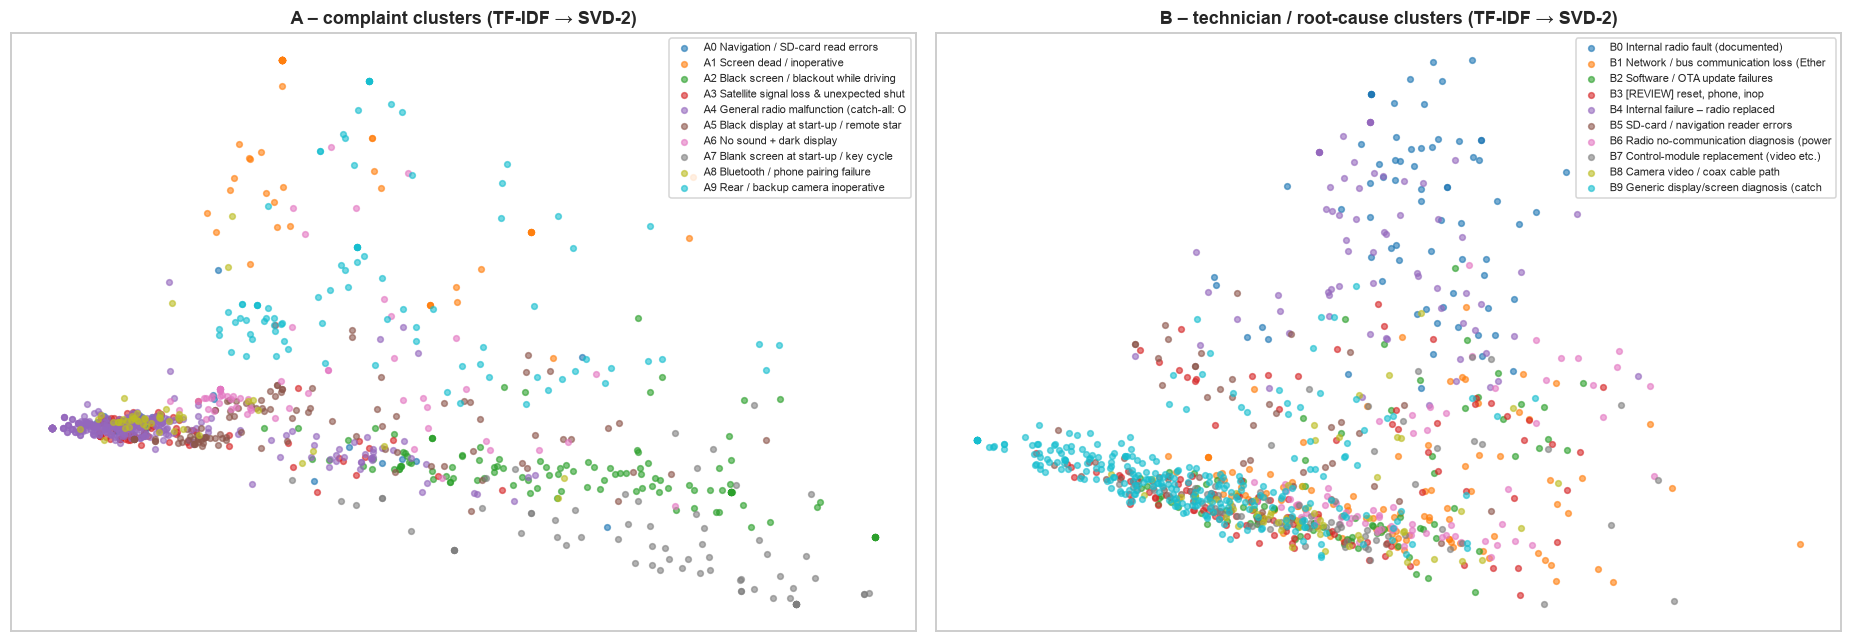

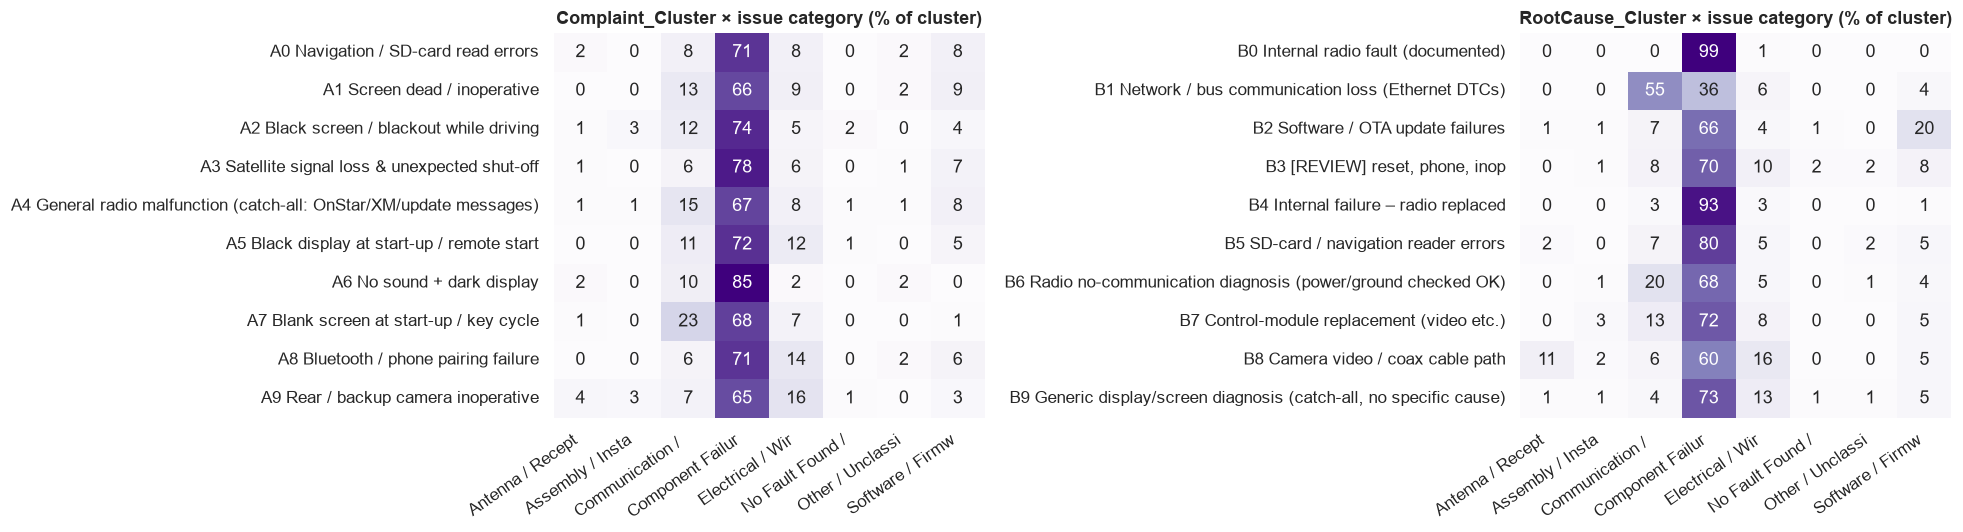

In [32]:
# ---- cluster visualisation: 2-D SVD projection ----
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
for a, (X, col, title) in zip(ax, [(ZA, 'Complaint_Cluster', 'A – complaint clusters'), (ZB, 'RootCause_Cluster', 'B – technician / root-cause clusters')]):
    Z = TruncatedSVD(2, random_state=0).fit_transform(X)
    for i, lab in enumerate(sorted(df[col].unique())):
        mk = (df[col] == lab).values; a.scatter(Z[mk, 0], Z[mk, 1], s=14, alpha=.6, color=sns.color_palette('tab10')[i % 10], label=lab[:42])
    a.set_title(title + ' (TF-IDF → SVD-2)'); a.legend(fontsize=7, loc='best'); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); savefig('clusters_scatter')

# cluster × issue category (row-normalised) + cluster sizes
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for a, col in zip(ax, ['Complaint_Cluster', 'RootCause_Cluster']):
    t = pd.crosstab(df[col], df['Issue_Category'], normalize='index') * 100
    sns.heatmap(t.round(0), annot=True, fmt='.0f', cmap='Purples', ax=a, cbar=False); a.set_title(f'{col} × issue category (% of cluster)'); a.set_ylabel(''); a.set_xlabel('')
    a.set_xticklabels([x.get_text()[:16] for x in a.get_xticklabels()], rotation=35, ha='right')
plt.tight_layout(); savefig('cluster_vs_category')

In [33]:
# ---- LDA topic model (independent check) ----
cv = CountVectorizer(stop_words=STOP, min_df=8, max_df=0.5, ngram_range=(1, 1))
Xc = cv.fit_transform(df['txt_all'])
lda = LatentDirichletAllocation(n_components=6, learning_method='batch', random_state=42, max_iter=40).fit(Xc)
terms = np.array(cv.get_feature_names_out())
lda_topics = {t: list(terms[np.argsort(comp)[::-1][:10]]) for t, comp in enumerate(lda.components_)}
df['LDA_topic'] = lda.transform(Xc).argmax(axis=1)
print('LDA topic sizes:', df['LDA_topic'].value_counts().sort_index().to_dict())
for t, w in lda_topics.items(): print(f'topic {t}: ', ', '.join(w))
RES['lda'] = {int(t): w for t, w in lda_topics.items()}
RES['lda_sizes'] = {int(k): int(v) for k, v in df['LDA_topic'].value_counts().sort_index().items()}

LDA topic sizes: {0: 154, 1: 150, 2: 127, 3: 254, 4: 144, 5: 171}
topic 0:  start, module, communication, internal, signal, power, screen, ground, failure, advised
topic 1:  camera, module, inop, internal, cable, rear, video, fault, coax, screen
topic 2:  card, error, navigation, audio, message, internal, antenna, nav, play, change
topic 3:  screen, display, blank, internal, fault, black, audio, controls, sound, power
topic 4:  ground, power, ethernet, communication, circuits, bus, screen, set, circuit, data
topic 5:  update, software, phone, updates, advised, failed, reset, tried, available, bluetooth


## 8. Root-cause synthesis
Combine what the clusters, tags and codes say about each recurring failure group: dominant symptom tags, most frequent component, how it is fixed, how early it fails, and where it is built.

In [34]:
def profile(col):
    rows = []
    for lab, sub in df.groupby(col):
        sym = pd.Series(Counter(t for x in sub['Mined_Failure_Condition'] for t in x if t != 'Unspecified')).sort_values(ascending=False)
        comp = pd.Series(Counter(t for x in sub['Mined_Failure_Component'] for t in x if t != 'Unspecified')).sort_values(ascending=False)
        rows.append({'cluster': lab, 'events': len(sub), 'share_%': round(len(sub)/len(df)*100, 1),
                     'top symptoms': ', '.join(sym.head(3).index), 'top components': ', '.join(comp.head(3).index),
                     'main issue category': sub['Issue_Category'].mode()[0], 'part replaced %': round(sub['part_replaced'].mean()*100),
                     'reprogram only %': round((sub['reprogrammed'] & ~sub['part_replaced']).mean()*100), 'TAC escalated %': round(sub['escalated_tac'].mean()*100),
                     'median days in service': sub['days_in_service_clean'].median(), 'top plant': sub['BUILD_PLANT_DESC'].mode()[0]})
    return pd.DataFrame(rows).sort_values('events', ascending=False)
profA, profB = profile('Complaint_Cluster'), profile('RootCause_Cluster')
display(profA); display(profB)
RES['profA'] = profA.to_dict(orient='records'); RES['profB'] = profB.to_dict(orient='records')
RES['termsA'] = {LABELS_A[c]: v for c, v in top_terms(vecA, kmA).items()}; RES['termsB'] = {LABELS_B[c]: v for c, v in top_terms(vecB, kmB).items()}

,cluster,events,share_%,top symptoms,top components,main issue category,part replaced %,reprogram only %,TAC escalated %,median days in service,top plant
4,A4 General radio malfunction (catch-all: OnStar/XM/update messages),326,32.6,"Inoperative / Dead, Intermittent Operation, Communication Loss / Network Fault","Radio / Head Unit, Display / Screen, Satellite Radio (XM)",Component Failure,82,11,29,240.0,Flint
2,A2 Black screen / blackout while driving,119,11.9,"Black / Blank Screen, Intermittent Operation, Inoperative / Dead","Radio / Head Unit, Display / Screen, Rear Camera",Component Failure,87,8,27,276.5,Silao
5,A5 Black display at start-up / remote start,102,10.2,"Inoperative / Dead, Black / Blank Screen, Intermittent Operation","Radio / Head Unit, Display / Screen, Software / Firmware",Component Failure,86,13,35,171.5,Flint
9,A9 Rear / backup camera inoperative,89,8.9,"Rear Camera Issue, Inoperative / Dead, Intermittent Operation","Rear Camera, Radio / Head Unit, Display / Screen",Component Failure,85,9,21,237.0,Fort Wayne
3,A3 Satellite signal loss & unexpected shut-off,82,8.2,"Reboot / Restart / Reset, Intermittent Operation, Satellite Signal Loss","Radio / Head Unit, Satellite Radio (XM), Display / Screen",Component Failure,89,6,37,222.0,Fort Wayne
7,A7 Blank screen at start-up / key cycle,71,7.1,"Black / Blank Screen, Intermittent Operation, Communication Loss / Network Fault","Radio / Head Unit, Display / Screen, Rear Camera",Component Failure,85,11,17,224.5,Fort Wayne
6,A6 No sound + dark display,60,6.0,"No Sound / Audio Loss, Inoperative / Dead, Intermittent Operation","Radio / Head Unit, Display / Screen, Satellite Radio (XM)",Component Failure,92,3,28,172.0,Fort Wayne
1,A1 Screen dead / inoperative,53,5.3,"Inoperative / Dead, Communication Loss / Network Fault, No Sound / Audio Loss","Radio / Head Unit, Display / Screen, Satellite Radio (XM)",Component Failure,89,8,38,183.0,Flint
0,A0 Navigation / SD-card read errors,49,4.9,"Navigation / GPS Error, Error / Warning Message, Inoperative / Dead","Radio / Head Unit, Navigation / GPS, Display / Screen",Component Failure,80,8,47,265.0,Silao
8,A8 Bluetooth / phone pairing failure,49,4.9,"Bluetooth / Phone Connection Failure, Intermittent Operation, Inoperative / Dead","Radio / Head Unit, Bluetooth / Phone, Display / Screen",Component Failure,86,10,33,209.0,Fort Wayne


,cluster,events,share_%,top symptoms,top components,main issue category,part replaced %,reprogram only %,TAC escalated %,median days in service,top plant
9,"B9 Generic display/screen diagnosis (catch-all, no specific cause)",275,27.5,"Inoperative / Dead, Intermittent Operation, Black / Blank Screen","Radio / Head Unit, Display / Screen, Satellite Radio (XM)",Component Failure,85,9,29,222.5,Flint
3,"B3 [REVIEW] reset, phone, inop",116,11.6,"Inoperative / Dead, Intermittent Operation, Bluetooth / Phone Connection Failure","Radio / Head Unit, Display / Screen, Bluetooth / Phone",Component Failure,82,10,49,173.0,Silao
1,B1 Network / bus communication loss (Ethernet DTCs),106,10.6,"Communication Loss / Network Fault, Inoperative / Dead, Black / Blank Screen","Radio / Head Unit, Display / Screen, Telematics / OnStar",Communication / Network Fault,91,4,31,261.0,Fort Wayne
2,B2 Software / OTA update failures,90,9.0,"Inoperative / Dead, Reboot / Restart / Reset, Intermittent Operation","Radio / Head Unit, Display / Screen, Software / Firmware",Component Failure,73,24,36,305.0,Fort Wayne
7,B7 Control-module replacement (video etc.),79,7.9,"Black / Blank Screen, Inoperative / Dead, Intermittent Operation","Radio / Head Unit, Display / Screen, Rear Camera",Component Failure,86,10,30,220.0,Lansing Delta
6,B6 Radio no-communication diagnosis (power/ground checked OK),74,7.4,"Inoperative / Dead, Black / Blank Screen, Communication Loss / Network Fault","Radio / Head Unit, Display / Screen, Rear Camera",Component Failure,88,11,19,247.0,Flint
0,B0 Internal radio fault (documented),70,7.0,"Black / Blank Screen, Inoperative / Dead, Intermittent Operation","Radio / Head Unit, Display / Screen, Rear Camera",Component Failure,94,3,14,195.0,Flint
4,B4 Internal failure – radio replaced,67,6.7,"Inoperative / Dead, Black / Blank Screen, Intermittent Operation","Radio / Head Unit, Display / Screen, Satellite Radio (XM)",Component Failure,87,9,13,240.0,Silao
8,B8 Camera video / coax cable path,62,6.2,"Rear Camera Issue, Inoperative / Dead, Intermittent Operation","Radio / Head Unit, Rear Camera, Display / Screen",Component Failure,84,10,29,236.0,Fort Wayne
5,B5 SD-card / navigation reader errors,61,6.1,"Navigation / GPS Error, Inoperative / Dead, Error / Warning Message","Radio / Head Unit, Navigation / GPS, Display / Screen",Component Failure,84,2,39,175.0,Silao


In [35]:
# Do clusters concentrate in particular plants / models? (chi-square, with Cramér's V as effect size)
def cramers(a, b):
    t = pd.crosstab(a, b); t = t.loc[t.sum(axis=1) >= 15, t.sum() >= 15]
    chi2, p, dof, _ = stats.chi2_contingency(t); v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))); return round(chi2, 1), round(p, 4), round(v, 3)
for name, a, b in [('Root-cause cluster × plant', df['RootCause_Cluster'], df['BUILD_PLANT_DESC']), ('Complaint cluster × plant', df['Complaint_Cluster'], df['BUILD_PLANT_DESC']),
                   ('Root-cause cluster × make', df['RootCause_Cluster'], df['MAKE']), ('Issue category × make', df['Issue_Category'], df['MAKE']),
                   ('Issue category × plant', df['Issue_Category'], df['BUILD_PLANT_DESC'])]:
    print(f'{name:32s} chi2 / p / Cramér V =', cramers(a, b))
RES['assoc'] = {n: cramers(a, b) for n, a, b in [('RC×plant', df['RootCause_Cluster'], df['BUILD_PLANT_DESC']), ('Complaint×plant', df['Complaint_Cluster'], df['BUILD_PLANT_DESC']),
                                               ('RC×make', df['RootCause_Cluster'], df['MAKE']), ('Cat×make', df['Issue_Category'], df['MAKE'])]}

Root-cause cluster × plant       chi2 / p / Cramér V = (np.float64(60.4), np.float64(0.2567), np.float64(0.101))
Complaint cluster × plant        chi2 / p / Cramér V = (np.float64(72.5), np.float64(0.0472), np.float64(0.11))
Root-cause cluster × make        chi2 / p / Cramér V = (np.float64(53.9), np.float64(0.0016), np.float64(0.134))
Issue category × make            chi2 / p / Cramér V = (np.float64(16.8), np.float64(0.0527), np.float64(0.076))
Issue category × plant           chi2 / p / Cramér V = (np.float64(14.6), np.float64(0.6882), np.float64(0.071))


## 9. Export
* `outputs/Task2_enriched_dataset.csv` / `.xlsx` – all original columns + cleaned fields + mined tags + issue category + cluster labels
* `outputs/figures/*.png` – charts reused in the report
* `outputs/key_results.json` – numbers consumed by the stakeholder report

In [38]:
export = df.copy()
list_cols = ['Mined_Trigger', 'Mined_Failure_Component', 'Mined_Failure_Condition', 'Mined_Additional_Context', 'Mined_Fix_Component', 'Mined_Fix_Condition', 'DTC_codes']
for c in list_cols: export[c] = export[c].map(lambda x: '; '.join(x))
# keep the 5 hand-labelled example columns but rename them so they are not confused with the mined ones
export = export.rename(columns={c: 'Provided_' + c.replace(' ', '_') for c in ['Trigger', 'Failure Component', 'Failure Condition', 'Additional Context', 'Fix Component', 'Fix Condition']})
drop = [c for c in export.columns if c.startswith('n_') or c.startswith('txt_')] + ['ClusterA', 'ClusterB']
front = ['Event id', 'Opened date', 'MAKE', 'MODEL', 'BUILD_PLANT_DESC', 'COMPLAINT_CD_DESC', 'CAUSAL_CD_DESC',
         'Mined_Trigger', 'Mined_Failure_Component', 'Mined_Failure_Condition', 'Mined_Additional_Context', 'Mined_Fix_Component', 'Mined_Fix_Condition',
         'Issue_Category', 'Issue_Category_Secondary', 'Complaint_Cluster', 'RootCause_Cluster', 'LDA_topic']
export = export.drop(columns=drop)
export = export[front + [c for c in export.columns if c not in front]]
export.to_csv(f'{OUT}/Task2_enriched_dataset.csv', index=False)

tag_dict = pd.DataFrame([(fam, tag, rx[0][:160] + ('…' if len(rx[0]) > 160 else ''), rx[1]) for fam, d in
                         [('Failure Component', FAILURE_COMPONENTS), ('Failure Condition', FAILURE_CONDITIONS), ('Trigger', TRIGGERS), ('Additional Context', ADDITIONAL_CONTEXT)]
                         for tag, rx in d.items()], columns=['family', 'tag', 'pattern (truncated)', 'text scope'])
with pd.ExcelWriter(f'{OUT}/Task2_enriched_dataset.xlsx', engine='openpyxl') as xw:
    export.to_excel(xw, sheet_name='Enriched data', index=False)
    pd.DataFrame({'Issue category': cat_counts.index, 'Events': cat_counts.values, 'Share %': (cat_counts.values / len(df) * 100).round(1)}).to_excel(xw, sheet_name='Issue categories', index=False)
    profA.to_excel(xw, sheet_name='Complaint clusters', index=False); profB.to_excel(xw, sheet_name='Root-cause clusters', index=False)
    tag_dict.to_excel(xw, sheet_name='Tag dictionary', index=False)
    ws = xw.book['Enriched data']; ws.freeze_panes = 'B2'
    for col in ws.columns: ws.column_dimensions[col[0].column_letter].width = min(40, max(12, len(str(col[0].value)) + 2))
json.dump(RES, open(f'{OUT}/key_results.json', 'w'), indent=1, default=str)
print('exported', export.shape, '→', os.listdir(OUT))

exported (1000, 58) → ['figures', 'key_results.json', 'Task2_enriched_dataset.csv', 'Task2_enriched_dataset.xlsx']


In [5]:
%pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---- ----------------------------------- 3.9/37.4 MB 23.2 MB/s eta 0:00:02
   --------- ------------------------------ 8.9/37.4 MB 22.7 MB/s eta 0:00:02
   -------------- ------------------------- 13.6/37.4 MB 22.7 MB/s eta 0:00:02
   ------------------ --------------------- 17.6/37.4 MB 21.7 MB/s eta 0:00:01
   ----------------------- ---------------- 22.0/37.4 MB 21.3 MB/s eta 0:00:01
   ---------------------------- ----------- 26.2/37.4 MB 21.0 MB/s eta 0:00:01
   -------------------------------- ------- 30.4/37.4 MB 20.8 MB/s eta 0:00:01
   ------------------------------------ --- 34.3/37.4 MB 20.6 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 20.5 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 20.5 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 20.5 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 20.5 M


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import scipy
print(scipy.__version__)

1.18.1


In [27]:
%pip install scikit-learn

  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.4 MB 17.4 MB/s eta 0:00:01
   ---------------------- ----------------- 4.7/8.4 MB 16.8 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.4 MB 14.5 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 13.4 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 13.4 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 13.4 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 13.4 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 13.4 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 4.8 MB/s  0:00:01
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------------- -------------------------- 1/3 [narwhals]
   ------------- -------------------------- 1/3 [narwha


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
